# Análise bivariada e evidências para as transformações

Continuação da limpeza (`Limpeza/Limpeza_V2.ipynb`). Usa o `UCMF_limpo.csv` (resultado da limpeza) e o `UCMF_raw.csv` (dado original) para:

1. comparar FC e IDADE antes e depois da limpeza;
2. analisar cada variável contra o alvo `NORMAL X ANORMAL`;
3. verificar se a relação entre FC e alvo é explicada pela idade;
4. reunir as evidências que justificam as transformações da modelagem;
5. completar a tabela de transformações (vazamento, colunas raras, `pa_medida`, imputação, divisão por paciente);
6. aplicar as transformações com um pré-processador que aprende só no treino e exportar treino/teste para a A2.

**Um único teste para todas as variáveis: qui-quadrado (α = 0,05).** As numéricas são divididas em quartis, e todas as variáveis ganham o mesmo resumo de efeito (% de Anormal na categoria ou faixa de maior vs menor proporção), comparável numa só tabela.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency, spearmanr

pd.set_option('display.max_colwidth', None)

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'UCMF_raw.csv').exists())
PASTA = RAIZ / 'Análise Bivariada'
FIG = PASTA / 'figuras'   
TAB = PASTA / 'tabelas'   
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(RAIZ / 'UCMF_raw.csv')
df_limpo = pd.read_csv(RAIZ / 'Limpeza' / 'UCMF_limpo.csv')

ALVO = 'NORMAL X ANORMAL'
ALFA = 0.05
# Categoria (ou faixa) com menos de 30 registros não entra no resumo do efeito: com
# tão poucos casos, a % de Anormal oscila demais para ser comparada.
N_MIN = 30

# Mesmas faixas etárias da limpeza (etapa 4.1), para os resultados serem comparáveis.
FAIXAS = [0, 1, 5, 10, 15, 19]
ROTULOS_FAIXAS = ['0–1', '1–5', '5–10', '10–15', '15–19']
faixa_etaria = pd.cut(df_limpo['IDADE'], bins=FAIXAS, labels=ROTULOS_FAIXAS, include_lowest=True)

print(f'df_raw: {df_raw.shape} | df_limpo: {df_limpo.shape}')

df_raw: (12873, 21) | df_limpo: (10576, 51)


In [2]:
COR = {'Normal': '#2a78d6', 'Anormal': '#eb6834'}
COR_UNICA = COR['Normal']                     # figuras com uma única série
TINTA, TINTA_2, GRADE, EIXO = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.titlesize': 14,
    'text.color': TINTA, 'axes.labelcolor': TINTA, 'axes.titlecolor': TINTA,
    'axes.edgecolor': EIXO, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
})


def salvar(fig, nome):
    fig.savefig(FIG / f'{nome}.png', dpi=300, bbox_inches='tight')
    plt.show()


def exportar(tabela, nome):
    tabela.to_csv(TAB / f'{nome}.csv', index=False, encoding='utf-8-sig')

def num(x, casas=1):
    return f'{x:.{casas}f}'.replace('.', ',')


def fmt_n(n):
    return f'{int(n):,}'.replace(',', '.')


def fmt_p(p):
    return '< 0,001' if p < 0.001 else num(p, 3)


def p_txt(p):
    """p-valor para usar dentro de frases: 'p < 0,001' ou 'p = 0,234'."""
    return 'p < 0,001' if p < 0.001 else f'p = {num(p, 3)}'

In [3]:
# MOTIVO1 virou colunas binárias na limpeza (etapa 7). Para analisá-lo como uma variável
# só, reconstruímos a categoria a partir das 5 colunas que vieram dele: cada linha tem
# no máximo uma delas marcada; sem nenhuma, o motivo não foi registrado (NaN, como os
# ausentes das outras variáveis).
COLS_MOTIVO1 = {
    'motivo_parecer_cardiologico': 'Parecer cardiológico',
    'motivo_suspeita_de_cardiopatia': 'Suspeita de cardiopatia',
    'motivo_cardiopatia_ja_estabelecida': 'Cardiopatia já estabelecida',
    'motivo_check_up': 'Check-up',
    'motivo_outro': 'Outro',
}
marcados = df_limpo[list(COLS_MOTIVO1)]
assert marcados.sum(axis=1).max() == 1, 'linha com mais de um MOTIVO1'
MOTIVO1 = marcados.idxmax(axis=1).map(COLS_MOTIVO1).where(marcados.sum(axis=1) == 1).rename('MOTIVO1')

# Só a PPA recalculada existe no df_limpo. A ordem clínica é mantida nas tabelas.
PPA = pd.Categorical(df_limpo['PPA_calc'],
                     categories=['Normal', 'Pré-hipertensão', 'HAS estágio 1', 'HAS estágio 2'],
                     ordered=True)
PPA = pd.Series(PPA, index=df_limpo.index, name='PPA')

print(MOTIVO1.value_counts(dropna=False).to_string())

MOTIVO1
Parecer cardiológico           4795
Suspeita de cardiopatia        3804
Cardiopatia já estabelecida     986
Check-up                        625
Outro                           266
NaN                             100


## Parte 1 – FC x IDADE, antes e depois da limpeza

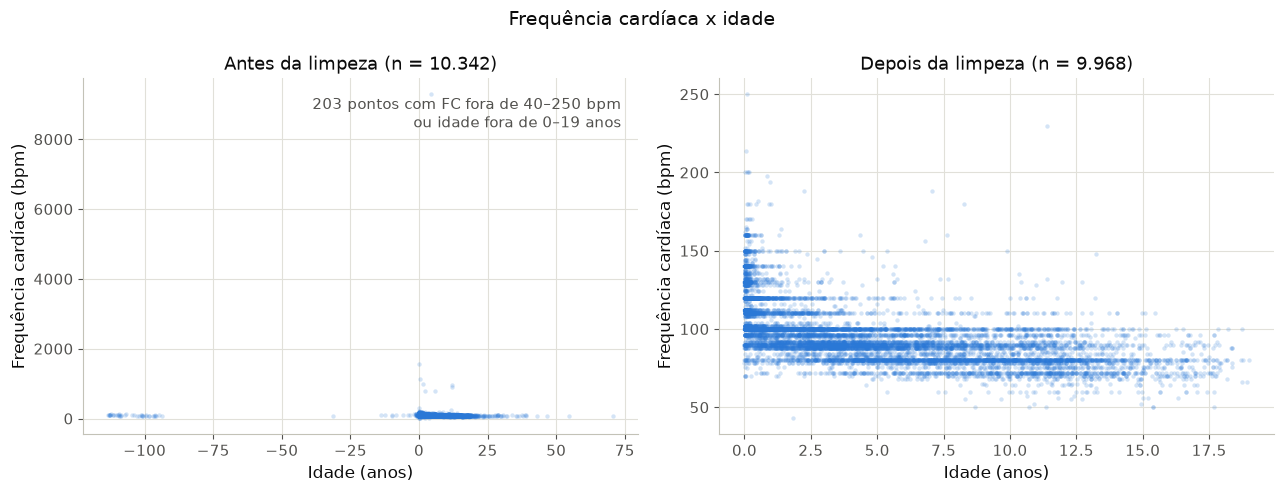

In [4]:

fc_bruta = pd.to_numeric(df_raw['FC'], errors='coerce')
idade_bruta = pd.to_numeric(df_raw['IDADE'], errors='coerce')
tem_bruto = fc_bruta.notna() & idade_bruta.notna()
fora_faixa = tem_bruto & (~fc_bruta.between(40, 250) | ~idade_bruta.between(FAIXAS[0], FAIXAS[-1]))
tem_limpo = df_limpo['FC'].notna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(idade_bruta[tem_bruto], fc_bruta[tem_bruto], s=10, alpha=0.2, color=COR_UNICA, linewidths=0)
ax1.set_title(f'Antes da limpeza (n = {fmt_n(tem_bruto.sum())})')
ax1.text(0.97, 0.95, f'{fora_faixa.sum()} pontos com FC fora de 40–250 bpm\nou idade fora de {FAIXAS[0]}–{FAIXAS[-1]} anos',
         transform=ax1.transAxes, ha='right', va='top', fontsize=11, color=TINTA_2)
ax2.scatter(df_limpo.loc[tem_limpo, 'IDADE'], df_limpo.loc[tem_limpo, 'FC'],
            s=10, alpha=0.2, color=COR_UNICA, linewidths=0)
ax2.set_title(f'Depois da limpeza (n = {fmt_n(tem_limpo.sum())})')
for ax in (ax1, ax2):
    ax.set_xlabel('Idade (anos)')
    ax.set_ylabel('Frequência cardíaca (bpm)')
fig.suptitle('Frequência cardíaca x idade')
fig.tight_layout()
salvar(fig, 'fc_idade_antes_depois')

#### Interpretação
O painel da esquerda usa o CSV bruto (FC convertida para número; o que não converte fica de fora) em escala completa, justamente para mostrar os valores impossíveis que a limpeza removeu. O da direita usa a base limpa.
* alpha baixo porque são ~10 mil pontos sobrepostos: a densidade aparece pela transparência.

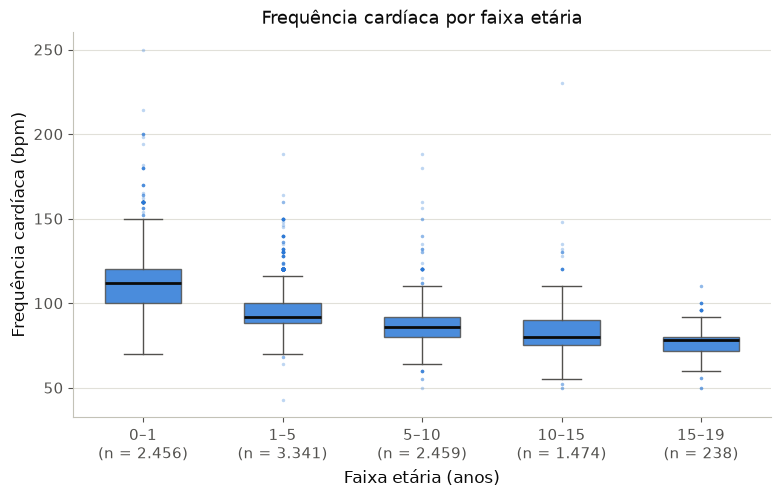

In [5]:
fc_por_faixa_dados = [df_limpo.loc[faixa_etaria == f, 'FC'].dropna() for f in ROTULOS_FAIXAS]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(fc_por_faixa_dados, widths=0.55, patch_artist=True,
                tick_labels=[f'{f}\n(n = {fmt_n(len(d))})' for f, d in zip(ROTULOS_FAIXAS, fc_por_faixa_dados)],
                medianprops=dict(color=TINTA, linewidth=2),
                whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                flierprops=dict(marker='o', markersize=2.5, alpha=0.3,
                                markerfacecolor=COR_UNICA, markeredgewidth=0))
for caixa in bp['boxes']:
    caixa.set(facecolor=COR_UNICA, alpha=0.85, edgecolor=TINTA_2)
ax.set_xlabel('Faixa etária (anos)')
ax.set_ylabel('Frequência cardíaca (bpm)')
ax.set_title('Frequência cardíaca por faixa etária')
ax.grid(axis='x', visible=False)
salvar(fig, 'fc_por_faixa_etaria')

#### Interpretação
Boxplot por faixa etária: resume a queda da FC com a idade sem o excesso de pontos do
gráfico de dispersão. O n de cada faixa vai no rótulo para o leitor saber o peso de cada caixa.

In [6]:
# Mediana e quartis (e não média e desvio) porque a FC é assimétrica e tem valores extremos.
fc_por_faixa = (df_limpo.groupby(faixa_etaria, observed=True)['FC']
                .agg(n='count', Q1=lambda s: s.quantile(0.25), mediana='median',
                     Q3=lambda s: s.quantile(0.75))
                .round(1).reset_index().rename(columns={'IDADE': 'faixa etária (anos)'}))
display(fc_por_faixa)
exportar(fc_por_faixa, 'fc_por_faixa')

,faixa etária (anos),n,Q1,mediana,Q3
0,0–1,2456,100.0,112.0,120.0
1,1–5,3341,88.0,92.0,100.0
2,5–10,2459,80.0,86.0,92.0
3,10–15,1474,75.0,80.0,90.0
4,15–19,238,72.0,78.0,80.0


In [7]:
# Spearman, e não Pearson: a relação entre FC e idade não é necessariamente linear (a
# queda é mais rápida nos primeiros anos) e as duas variáveis são assimétricas. Spearman
# usa a ordem dos valores, então mede qualquer relação que só suba ou só desça.
par = df_limpo[['IDADE', 'FC']].dropna()
rho_fc_idade, p_fc_idade = spearmanr(par['IDADE'], par['FC'])
print(f'Spearman FC x IDADE: rho = {num(rho_fc_idade, 3)}, {p_txt(p_fc_idade)} (n = {fmt_n(len(par))})')

Spearman FC x IDADE: rho = -0,692, p < 0,001 (n = 9.968)


#### Complemento: IDADE × Peso

Mostra por que Peso (e Altura) são redundantes com a IDADE, o que sustenta a decisão da Parte 4 de manter IDADE e IMC no modelo, e não Peso e Altura.

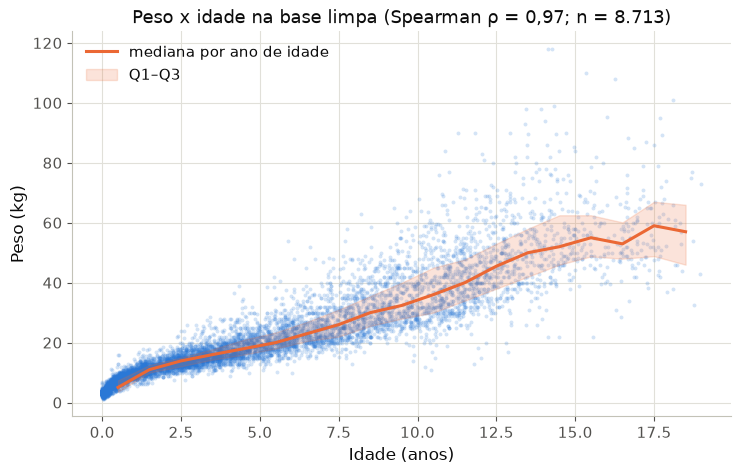

Spearman IDADE x Peso: rho = 0,968, p < 0,001
Mediana do peso por ano de idade (kg): {0.0: 5.0, 1.0: 11.0, 2.0: 13.9, 3.0: 16.0, 4.0: 18.0, 5.0: 20.0, 6.0: 23.0, 7.0: 26.0, 8.0: 30.0, 9.0: 32.4, 10.0: 36.0, 11.0: 40.0, 12.0: 45.5, 13.0: 50.0, 14.0: 52.0, 15.0: 55.0, 16.0: 53.0, 17.0: 59.0, 18.0: 57.0}


In [8]:
from scipy.stats import spearmanr

# Relação IDADE x Peso na base limpa (complementar): mostra por que Peso/Altura são redundantes com a IDADE
par_ip = df_limpo[['IDADE', 'Peso']].dropna()
rho_ip, p_ip = spearmanr(par_ip['IDADE'], par_ip['Peso'])
por_ano = par_ip.groupby(np.floor(par_ip['IDADE']))['Peso'].describe()[['25%', '50%', '75%']]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(par_ip['IDADE'], par_ip['Peso'], s=8, alpha=0.2, color=COR_UNICA, linewidths=0)
ax.plot(por_ano.index + 0.5, por_ano['50%'], color=COR['Anormal'], linewidth=2.2, label='mediana por ano de idade')
ax.fill_between(por_ano.index + 0.5, por_ano['25%'], por_ano['75%'], color=COR['Anormal'], alpha=0.18, label='Q1–Q3')
ax.set_xlabel('Idade (anos)'); ax.set_ylabel('Peso (kg)')
ax.set_title(f'Peso x idade na base limpa (Spearman ρ = {num(rho_ip, 2)}; n = {fmt_n(len(par_ip))})')
ax.legend(frameon=False)
salvar(fig, 'idade_peso')
print(f'Spearman IDADE x Peso: rho = {num(rho_ip, 3)}, {p_txt(p_ip)}')
print('Mediana do peso por ano de idade (kg):', por_ano['50%'].round(1).head(19).to_dict())

#### Interpretação
A correlação de Spearman entre IDADE e Peso é 0,97. O peso mediano sobe de 5 kg (menos de 1 ano) para 53–59 kg (15 a 18 anos), com dispersão crescente: adolescentes variam muito mais. Peso e Altura carregam quase a mesma informação que a IDADE.

## Parte 2 – Cada variável contra o alvo

Um só teste para tudo: **qui-quadrado**. As regras:

- **Numéricas:** viram quartis, e o qui-quadrado compara a % de Anormal entre as quatro faixas.
- **Categorias raras:** categorias com menos de 30 registros são agrupadas em "Outras". Se "Outras" continuar com menos de 30, ou se uma variável binária tiver menos de 30 casos positivos, ela fica fora do teste e aparece na tabela como "n insuficiente". Isso também evita frequências esperadas abaixo de 5, que deixariam o qui-quadrado impreciso.
- **Resumo do efeito:** "% Anormal: maior = a% vs menor = b%", o mesmo formato para todas as variáveis.
- **Relações não monotônicas:** nas numéricas, a maior e a menor % de Anormal nem sempre estão nos quartis extremos. Na PA sistólica, por exemplo, o resumo compara Q1 com Q2. Quando isso acontece, a coluna "observação" avisa, e a interpretação deve considerar que a % de Anormal não sobe nem desce de forma contínua com o valor.
- **Quartis fundidos:** quando muitos valores se repetem (PA diastólica quase sempre 60 ou 70), dois quartis têm o mesmo limite e viram uma faixa só, rotulada "Q1–Q2".

In [9]:
def em_quartis(serie, casas=1):
    """Divide uma numérica em quartis rotulados com os valores observados em cada faixa.

    Com muitos valores repetidos (ex.: PA diastólica quase sempre 60 ou 70), dois quartis
    podem ter o mesmo limite e se fundir numa faixa só; o rótulo mostra isso ("Q1–Q2").
    """
    # retbins devolve os limites exatos; os dos rótulos do qcut vêm arredondados.
    q, bordas = pd.qcut(serie, q=4, duplicates='drop', retbins=True)
    limites = serie.groupby(q, observed=True).agg(['min', 'max'])
    # Cada quartil pertence à primeira faixa cujo limite superior alcança o seu. isclose
    # evita que diferenças de arredondamento separem limites que são iguais.
    cortes = serie.quantile([0.25, 0.5, 0.75, 1.0]).to_numpy()
    direitas = bordas[1:]
    faixa_do_quartil = [next(j for j, d in enumerate(direitas) if c <= d or np.isclose(c, d))
                        for c in cortes]
    rotulos = []
    for j, (lo, hi) in enumerate(zip(limites['min'], limites['max'])):
        cobertos = [k + 1 for k, jj in enumerate(faixa_do_quartil) if jj == j]
        nome = f'Q{cobertos[0]}' if len(cobertos) == 1 else f'Q{cobertos[0]}–Q{cobertos[-1]}'
        rotulos.append(f'{nome} ({num(lo, casas)}–{num(hi, casas)})')
    nota = '' if len(limites) == 4 else 'valores repetidos: quartis com o mesmo limite foram fundidos'
    return q.cat.rename_categories(rotulos), nota


def testar(serie, nome, tipo, casas=1, mostrar=True):
    """Qui-quadrado entre uma variável e o alvo, com o mesmo resumo de efeito para todas.

    tipo: 'categórica', 'binária' ou 'numérica (quartis)'. Usa só as linhas sem nulo.
    """
    obs = []
    x = serie
    if tipo == 'numérica (quartis)':
        x, nota = em_quartis(serie, casas)
        if nota:
            obs.append(nota)
    elif tipo == 'binária':
        x = serie.map({1: 'sim', 0: 'não'})
    dados = pd.DataFrame({'x': x, 'alvo': df_limpo.loc[serie.index, ALVO]}).dropna()

    if tipo == 'binária' and (dados['x'] == 'sim').sum() < N_MIN:
        n_sim = int((dados['x'] == 'sim').sum())
        return {'variável': nome, 'tipo': tipo, 'teste': 'não testada', 'n': len(dados), 'p': np.nan,
                'resumo do efeito': f'n insuficiente (apenas {n_sim} casos "sim")',
                'diferença (p.p.)': np.nan, 'observação': 'menos de 30 casos positivos', 'tabela': None}

    if tipo == 'categórica':
        contagem = dados['x'].value_counts()
        raras = list(contagem[contagem < N_MIN].index)
        if raras:
            dados['x'] = dados['x'].astype(object).where(~dados['x'].isin(raras), 'Outras')
            n_outras = int((dados['x'] == 'Outras').sum())
            nomes = ', '.join(str(r) for r in raras)
            if n_outras < N_MIN:
                dados = dados[dados['x'] != 'Outras']
                obs.append(f'{nomes} (n = {n_outras}) fora do teste: n insuficiente')
            else:
                obs.append(f'{nomes} agrupadas em "Outras" (n = {n_outras})')

    tabela = pd.crosstab(dados['x'], dados['alvo'])[['Normal', 'Anormal']]
    _, p, _, esperadas = chi2_contingency(tabela)
    n_cat = tabela.sum(axis=1)
    pct = tabela['Anormal'] / n_cat * 100
    maior, menor = pct.idxmax(), pct.idxmin()
    if (esperadas < 5).any():
        obs.append(f'frequência esperada < 5 em {int((esperadas < 5).sum())} célula(s)')
    # Nas numéricas, o resumo "maior vs menor" só compara as faixas extremas se a relação for
    # monotônica (a % de Anormal só sobe ou só desce). Quando não é, isso fica registrado.
    if tipo == 'numérica (quartis)' and {maior, menor} != {tabela.index[0], tabela.index[-1]}:
        obs.append('relação não monotônica: maior e menor % de Anormal fora das faixas extremas')

    resultado = {
        'variável': nome, 'tipo': tipo, 'teste': 'qui-quadrado', 'n': int(n_cat.sum()), 'p': p,
        'resumo do efeito': f'% Anormal: {maior} = {num(pct[maior])}% vs {menor} = {num(pct[menor])}%',
        'diferença (p.p.)': round(pct[maior] - pct[menor], 1),
        'observação': '; '.join(obs),
        'tabela': tabela.assign(n=n_cat, **{'% Anormal': pct.round(1)}),
    }
    if mostrar:
        print(f'\n{nome} ({tipo}): qui-quadrado {p_txt(p)}, n = {fmt_n(n_cat.sum())}')
        display(resultado['tabela'])
        if obs:
            print('Obs.: ' + '; '.join(obs))
    return resultado

In [10]:
# Categóricas: tabela de contingência, % de Anormal e n por categoria, e o qui-quadrado.
CATEGORICAS = {
    'SOPRO': df_limpo['SOPRO'],
    'B2': df_limpo['B2'],
    'PULSOS': df_limpo['PULSOS'],
    'MOTIVO1': MOTIVO1,
    'SEXO': df_limpo['SEXO'],
    'PPA (recalculada)': PPA,
}
resultados = {nome: testar(serie, nome, 'categórica') for nome, serie in CATEGORICAS.items()}


SOPRO (categórica): qui-quadrado p < 0,001, n = 10.566


alvo,Normal,Anormal,n,% Anormal
x,,,,
Ausente,5918,663,6581,10.1
Contínuo,9,28,37,75.7
Sistólico,163,3785,3948,95.9


Obs.: Diastólico, Sistólico e diastólico (n = 9) fora do teste: n insuficiente

B2 (categórica): qui-quadrado p < 0,001, n = 10.568


alvo,Normal,Anormal,n,% Anormal
x,,,,
Desdobramento fixo,13,123,136,90.4
Hiperfonética,5,243,248,98.0
Normal,6059,3995,10054,39.7
Outro,9,56,65,86.2
Única,2,63,65,96.9



PULSOS (categórica): qui-quadrado p < 0,001, n = 10.539


alvo,Normal,Anormal,n,% Anormal
x,,,,
Amplos,6,37,43,86.0
Femorais diminuídos,2,33,35,94.3
Normais,6063,4367,10430,41.9
Outro,8,23,31,74.2


... (2 outputs left out)


SEXO (categórica): qui-quadrado p = 0,068, n = 10.107


alvo,Normal,Anormal,n,% Anormal
x,,,,
F,2351,1771,4122,43.0
M,3524,2461,5985,41.1



PPA (recalculada) (categórica): qui-quadrado p = 0,010, n = 2.546


alvo,Normal,Anormal,n,% Anormal
x,,,,
Normal,1365,760,2125,35.8
Pré-hipertensão,143,69,212,32.5
HAS estágio 1,105,64,169,37.9
HAS estágio 2,16,24,40,60.0


In [11]:
# Binárias (sintomas, motivos, indicadores de ausência e pa_medida): são muitas, então os
# resultados vão numa tabela só, com n e % de Anormal para "sim" e "não" e o p-valor.
BINARIAS = ([c for c in df_limpo if c.startswith('sint_') or c.startswith('motivo_')]
            + ['hda_ausente', 'pa_medida'])
linhas = []
for col in BINARIAS:
    r = testar(df_limpo[col], col, 'binária', mostrar=False)
    resultados[col] = r
    t = r['tabela']
    linhas.append({
        'variável': col,
        'n sim': int(t.loc['sim', 'n']) if t is not None else int((df_limpo[col] == 1).sum()),
        '% Anormal (sim)': t.loc['sim', '% Anormal'] if t is not None else np.nan,
        'n não': int(t.loc['não', 'n']) if t is not None else int((df_limpo[col] == 0).sum()),
        '% Anormal (não)': t.loc['não', '% Anormal'] if t is not None else np.nan,
        'p-valor': fmt_p(r['p']) if t is not None else 'n insuficiente',
    })
display(pd.DataFrame(linhas))

,variável,n sim,% Anormal (sim),n não,% Anormal (não),p-valor
0,motivo_ausente,100,50.0,10476,42.3,"0,149"
1,sint_assintomatico,6017,46.7,4559,36.8,"< 0,001"
2,sint_cianose,292,56.2,10284,42.0,"< 0,001"
3,sint_desmaio_tontura,184,28.3,10392,42.7,"< 0,001"
4,sint_dispneia,557,51.7,10019,41.9,"< 0,001"
5,sint_dor_precordial,508,32.3,10068,42.9,"< 0,001"
6,sint_ganho_de_peso,98,34.7,10478,42.5,"0,147"
7,sint_outro,150,44.7,10426,42.4,"0,631"
8,sint_palpitacao,411,29.4,10165,42.9,"< 0,001"
9,motivo_cardiopatia_adquirida,80,56.2,10496,42.3,"0,016"


In [12]:
# Numéricas: primeiro o descritivo por classe (mediana e quartis, porque as distribuições
# são assimétricas), para o texto do relatório; depois o qui-quadrado sobre os quartis.
NUMERICAS = {'IDADE': 1, 'FC': 0, 'Peso': 1, 'Altura': 0, 'IMC': 1, 'PA SISTOLICA': 0, 'PA DIASTOLICA': 0}

partes = {}
for classe in ('Normal', 'Anormal'):
    sub = df_limpo.loc[df_limpo[ALVO] == classe, list(NUMERICAS)]
    partes[classe] = pd.DataFrame({'n': sub.count(), 'Q1': sub.quantile(0.25),
                                   'mediana': sub.median(), 'Q3': sub.quantile(0.75)})
descritivo = pd.concat(partes, axis=1).round(1)
display(descritivo)

for col, casas in NUMERICAS.items():
    resultados[col] = testar(df_limpo[col], col, 'numérica (quartis)', casas=casas)

Normal                      Anormal                     
                   n    Q1 mediana     Q3       n    Q1 mediana     Q3
IDADE           6091   1.8     4.8    9.3    4485   0.4     2.7    6.5
FC              5774  80.0    90.0  100.0    4194  88.0    98.0  110.0
Peso            4995  11.6    18.0   31.0    3718   6.0    13.0   21.0
Altura          4143  81.0   105.0  134.0    3100  59.0    89.0  114.2
IMC             3954  15.5    17.0   19.3    2936  14.6    16.3   18.1
PA SISTOLICA    2937  95.0   100.0  110.0    1622  90.0   100.0  110.0
PA DIASTOLICA   2933  60.0    60.0   70.0    1617  60.0    60.0   65.0


IDADE (numérica (quartis)): qui-quadrado p < 0,001, n = 10.576


alvo,Normal,Anormal,n,% Anormal
x,,,,
"Q1 (0,0–1,0)",1026,1622,2648,61.3
"Q2 (1,0–3,8)",1584,1056,2640,40.0
"Q3 (3,8–8,2)",1627,1017,2644,38.5
"Q4 (8,2–19,0)",1854,790,2644,29.9



FC (numérica (quartis)): qui-quadrado p < 0,001, n = 9.968


alvo,Normal,Anormal,n,% Anormal
x,,,,
Q1 (43–80),1882,747,2629,28.4
Q2 (81–92),1775,1021,2796,36.5
Q3 (93–100),1162,1058,2220,47.7
Q4 (102–250),955,1368,2323,58.9



Peso (numérica (quartis)): qui-quadrado p < 0,001, n = 8.713


... (7 outputs left out)

Obs.: relação não monotônica: maior e menor % de Anormal fora das faixas extremas



PA DIASTOLICA (numérica (quartis)): qui-quadrado p = 0,007, n = 4.550

alvo,Normal,Anormal,n,% Anormal
x,,,,
Q1–Q2 (23–60),1936,1140,3076,37.1
Q3 (62–70),733,358,1091,32.8
Q4 (72–120),264,119,383,31.1


Obs.: valores repetidos: quartis com o mesmo limite foram fundidos


In [13]:
# Tabela-resumo única. Com ~10 mil pacientes, quase qualquer diferença dá p < 0,05: o
# p-valor só diz que a diferença provavelmente não é acaso, não que ela é grande. Por
# isso a tabela é ordenada pelo tamanho da diferença (em pontos percentuais de Anormal),
# e é esse tamanho que deve guiar a interpretação.
resumo = pd.DataFrame([{k: v for k, v in r.items() if k != 'tabela'} for r in resultados.values()])
resumo['p-valor'] = [fmt_p(p) if pd.notna(p) else '—' for p in resumo['p']]
resumo['significativo (α = 0,05)'] = ['sim' if p < ALFA else 'não' if pd.notna(p) else '—' for p in resumo['p']]
resumo = (resumo.sort_values('diferença (p.p.)', ascending=False, na_position='last')
          [['variável', 'tipo', 'teste', 'n', 'p-valor', 'significativo (α = 0,05)',
            'resumo do efeito', 'diferença (p.p.)', 'observação']]
          .reset_index(drop=True))
display(resumo)
exportar(resumo, 'bivariada_resumo')

,variável,tipo,teste,n,p-valor,"significativo (α = 0,05)",resumo do efeito,diferença (p.p.),observação
0,SOPRO,categórica,qui-quadrado,10566,"< 0,001",sim,"% Anormal: Sistólico = 95,9% vs Ausente = 10,1%",85.8,"Diastólico, Sistólico e diastólico (n = 9) fora do teste: n insuficiente"
1,B2,categórica,qui-quadrado,10568,"< 0,001",sim,"% Anormal: Hiperfonética = 98,0% vs Normal = 39,7%",58.2,
2,PULSOS,categórica,qui-quadrado,10539,"< 0,001",sim,"% Anormal: Femorais diminuídos = 94,3% vs Normais = 41,9%",52.4,Diminuídos (n = 13) fora do teste: n insuficiente
3,MOTIVO1,categórica,qui-quadrado,10476,"< 0,001",sim,"% Anormal: Cardiopatia já estabelecida = 71,2% vs Parecer cardiológico = 25,2%",46.0,
4,motivo_sopro,binária,qui-quadrado,10576,"< 0,001",sim,"% Anormal: sim = 76,4% vs não = 33,9%",42.6,
5,Peso,numérica (quartis),qui-quadrado,8713,"< 0,001",sim,"% Anormal: Q1 (1,2–9,0) = 63,1% vs Q4 (27,1–118,0) = 28,4%",34.7,
6,motivo_cardiopatia_congenita,binária,qui-quadrado,10576,"< 0,001",sim,"% Anormal: sim = 73,2% vs não = 39,6%",33.6,
7,Altura,numérica (quartis),qui-quadrado,7243,"< 0,001",sim,"% Anormal: Q1 (40–70) = 62,0% vs Q4 (127–198) = 29,1%",32.9,
8,motivo_cardiopatia_ja_estabelecida,binária,qui-quadrado,10576,"< 0,001",sim,"% Anormal: sim = 71,2% vs não = 39,4%",31.7,
9,motivo_parecer_cardiologico,binária,qui-quadrado,10576,"< 0,001",sim,"% Anormal: não = 56,7% vs sim = 25,2%",31.5,


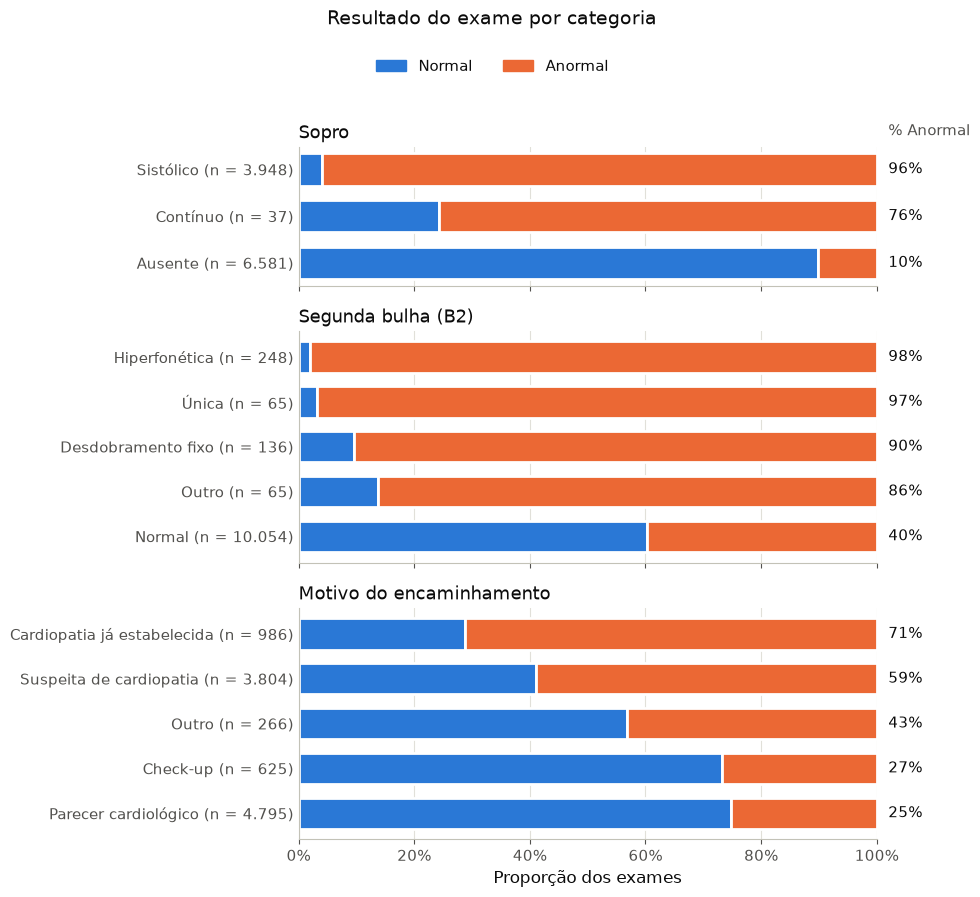

In [14]:
# Barras 100% empilhadas para as três categóricas mais importantes clinicamente. Cada
# barra soma 100%, então categorias de tamanhos muito diferentes ficam comparáveis; o n
# vai no rótulo e a % de Anormal à direita, para não depender só da cor.
PAINEIS = [('SOPRO', 'Sopro'), ('B2', 'Segunda bulha (B2)'), ('MOTIVO1', 'Motivo do encaminhamento')]
tabelas_painel = [resultados[v]['tabela'].sort_values('% Anormal') for v, _ in PAINEIS]

fig, eixos = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                          gridspec_kw={'height_ratios': [len(t) for t in tabelas_painel]})
for ax, (_, titulo), t in zip(eixos, PAINEIS, tabelas_painel):
    y = np.arange(len(t))
    pct_anormal = t['% Anormal']
    ax.barh(y, 100 - pct_anormal, color=COR['Normal'], edgecolor='white', linewidth=2, height=0.7)
    ax.barh(y, pct_anormal, left=100 - pct_anormal, color=COR['Anormal'],
            edgecolor='white', linewidth=2, height=0.7)
    ax.set_yticks(y, [f'{c} (n = {fmt_n(n)})' for c, n in zip(t.index, t['n'])])
    for yi, v in zip(y, pct_anormal):
        ax.text(102, yi, f'{num(v, 0)}%', va='center', fontsize=11, color=TINTA)
    ax.set_title(titulo, loc='left')
    ax.set_xlim(0, 100)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
eixos[0].text(102, len(tabelas_painel[0]) - 0.35, '% Anormal', fontsize=11, color=TINTA_2, va='bottom')
eixos[-1].xaxis.set_major_formatter(PercentFormatter())
eixos[-1].set_xlabel('Proporção dos exames')
fig.legend(handles=[Patch(color=COR['Normal'], label='Normal'), Patch(color=COR['Anormal'], label='Anormal')],
           loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.955))
fig.suptitle('Resultado do exame por categoria', y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.93))
salvar(fig, 'bivariada_categoricas')

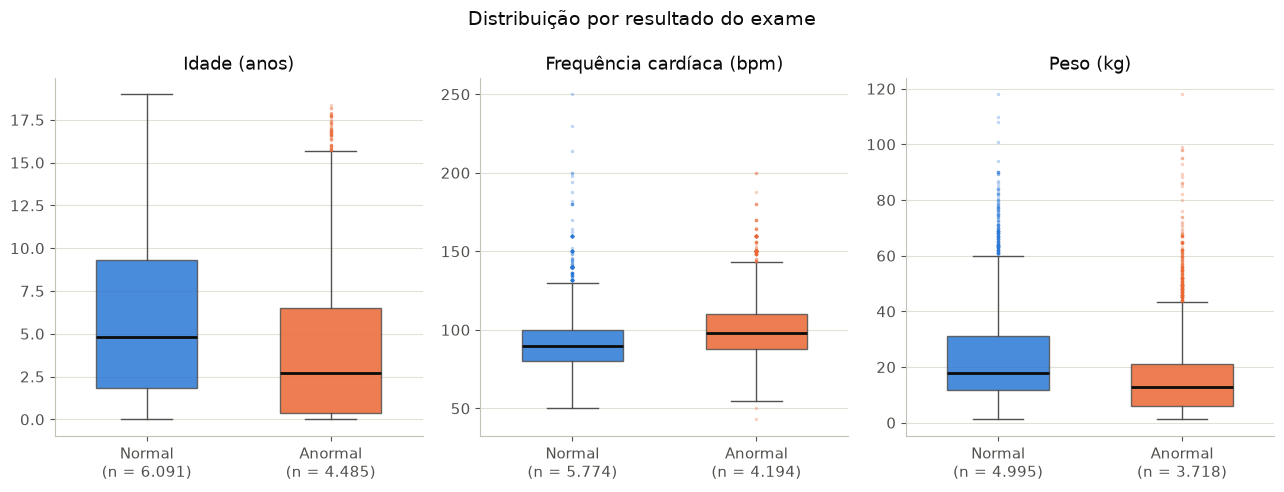

In [15]:
# Boxplots por classe para as três numéricas de maior interesse: mostram posição e
# dispersão de cada classe lado a lado, sem a perda de informação dos quartis.
PAINEIS_NUM = [('IDADE', 'Idade (anos)'), ('FC', 'Frequência cardíaca (bpm)'), ('Peso', 'Peso (kg)')]

fig, eixos = plt.subplots(1, 3, figsize=(13, 5))
for ax, (col, rotulo) in zip(eixos, PAINEIS_NUM):
    grupos = [df_limpo.loc[df_limpo[ALVO] == c, col].dropna() for c in ('Normal', 'Anormal')]
    bp = ax.boxplot(grupos, widths=0.55, patch_artist=True,
                    tick_labels=[f'{c}\n(n = {fmt_n(len(g))})' for c, g in zip(('Normal', 'Anormal'), grupos)],
                    medianprops=dict(color=TINTA, linewidth=2),
                    whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                    flierprops=dict(marker='o', markersize=2.5, alpha=0.3, markeredgewidth=0))
    for caixa, fliers, c in zip(bp['boxes'], bp['fliers'], ('Normal', 'Anormal')):
        caixa.set(facecolor=COR[c], alpha=0.85, edgecolor=TINTA_2)
        fliers.set_markerfacecolor(COR[c])
    ax.set_title(rotulo)
    ax.grid(axis='x', visible=False)
fig.suptitle('Distribuição por resultado do exame')
fig.tight_layout()
salvar(fig, 'bivariada_numericas')

#### Interpretação (cada variável × alvo)
- 31 das 40 variáveis testadas têm p < 0,05, o esperado com n grande; por isso a leitura é pelo tamanho da diferença.
- **SOPRO, a maior diferença:** 95,9% de Anormais com sopro sistólico × 10,1% com sopro ausente (85,8 p.p.).
- **B2:** hiperfonética 98,0% × normal 39,7% (58,2 p.p.). **PULSOS:** femorais diminuídos 94,3% × normais 41,9% (52,4 p.p.), mas essas categorias são raras.
- **Motivo:** "cardiopatia já estabelecida" 71,2% × "parecer cardiológico" 25,2% (46,0 p.p.); entre os encaminhados por cirurgia, 23,0% são Anormais.
- **Idade, Peso e Altura:** o primeiro quartil (os menores) tem 61–63% de Anormais e o último, 28–30% (diferença de 31–35 p.p.): bebês pequenos são o grupo de maior risco. **FC:** Q4 = 58,9% × Q1 = 28,4%.
- **PA:** pouca diferença (PAS 8,6 p.p., e não monotônica: a maior % está no Q1; PAD 6,0 p.p.).
- **SEXO:** sem associação (F 43,0% × M 41,1%; p = 0,068).
- **Vazamento de informação (*data leakage*):** SOPRO, B2, PULSOS e os `motivo_*` são achados do próprio exame ou da consulta e compõem o julgamento Normal/Anormal. Um modelo que os use "acerta" em parte porque o rótulo já está embutido neles. Na A2, treinar com e sem esse grupo (Parte 6).

## Parte 2.1 – Tamanho de efeito

O qui-quadrado por quartis compara todas as variáveis numa tabela só, mas **discretizar** uma numérica joga informação fora, e a diferença em p.p. oscila com categorias pequenas. Duas medidas complementares, que não dependem do n:
- **|r| (Mann-Whitney)** para numéricas: 0 = distribuições iguais nas duas classes; 1 = separação total.
- **V de Cramér** para categóricas: 0 = nenhuma associação; 1 = associação total.

Convenção usual: < 0,1 desprezível; 0,1–0,3 pequeno a moderado; > 0,3 grande.

NUMÉRICAS x alvo (Mann-Whitney)


,variável,n Anormal,n Normal,mediana Anormal,mediana Normal,AUC,|r| (tamanho do efeito),p
2,Peso,3718,4995,13.000,18.000,0.354,0.293,0.000
3,Altura,3100,4143,89.000,105.000,0.362,0.276,0.000
1,FC,4194,5774,98.000,90.000,0.637,0.274,0.000
0,IDADE,4485,6091,2.680,4.808,0.371,0.258,0.000
4,IMC,2936,3954,16.273,17.044,0.404,0.192,0.000
5,PA SISTOLICA,1622,2937,100.000,100.000,0.472,0.056,0.001
6,PA DIASTOLICA,1617,2933,60.000,60.000,0.472,0.056,0.001


CATEGÓRICAS x alvo (V de Cramér)


,variável,n,V de Cramér,p
0,SOPRO,10566,0.840,0.000
3,MOTIVO1,10476,0.366,0.000
1,B2,10568,0.239,0.000
2,PULSOS,10539,0.090,0.000
5,PPA (recalculada),2546,0.067,0.010
4,SEXO,10107,0.018,0.068


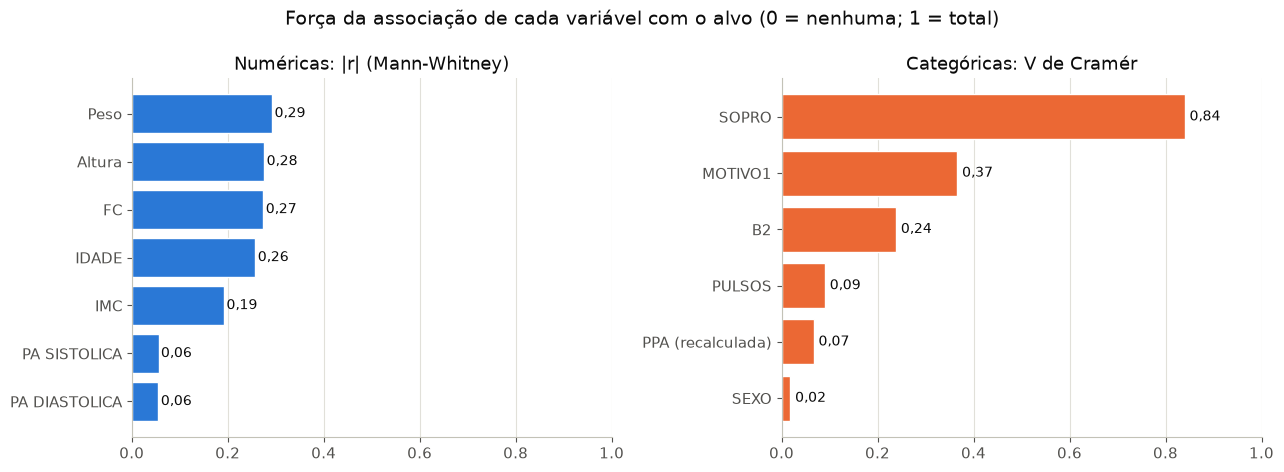

In [16]:
# Complemento ao qui-quadrado por quartis: tamanho de efeito SEM discretizar as numéricas.
#  - numéricas x alvo: Mann-Whitney U  ->  |r| (rank-biserial) = |2·AUC − 1|   (0 = igual; 1 = separação total)
#  - categóricas x alvo: qui-quadrado  ->  V de Cramér (0 a 1)
from scipy.stats import mannwhitneyu

linhas_num = []
for nome, casas in NUMERICAS.items():
    a = df_limpo.loc[df_limpo[ALVO] == 'Anormal', nome].dropna()
    n_ = df_limpo.loc[df_limpo[ALVO] == 'Normal', nome].dropna()
    U, p = mannwhitneyu(a, n_)
    auc = U / (len(a) * len(n_))                       # P(valor de um Anormal > valor de um Normal)
    linhas_num.append({'variável': nome, 'n Anormal': len(a), 'n Normal': len(n_),
                       'mediana Anormal': a.median(), 'mediana Normal': n_.median(),
                       'AUC': auc, '|r| (tamanho do efeito)': abs(2 * auc - 1), 'p': p})
forca_num = pd.DataFrame(linhas_num).sort_values('|r| (tamanho do efeito)', ascending=False)

def cramer_v(serie, min_n=N_MIN):
    """V de Cramér entre uma categórica e o alvo; categorias com n < 30 viram 'Outras' (ou saem se ainda ficarem < 30)."""
    d = pd.DataFrame({'x': serie.astype(object), 'y': df_limpo[ALVO]}).dropna()
    cont = d['x'].value_counts()
    raras = cont[cont < min_n].index
    d['x'] = d['x'].where(~d['x'].isin(raras), 'Outras')
    if (d['x'] == 'Outras').sum() < min_n:
        d = d[d['x'] != 'Outras']
    tab = pd.crosstab(d['x'], d['y'])
    chi2, p, _, _ = chi2_contingency(tab)
    return {'n': len(d), 'V de Cramér': np.sqrt(chi2 / (len(d) * (min(tab.shape) - 1))), 'p': p}

linhas_cat = [{'variável': nome, **cramer_v(serie)} for nome, serie in CATEGORICAS.items()]
forca_cat = pd.DataFrame(linhas_cat).sort_values('V de Cramér', ascending=False)

print('NUMÉRICAS x alvo (Mann-Whitney)'); display(forca_num.round(3))
print('CATEGÓRICAS x alvo (V de Cramér)'); display(forca_cat.round(3))
exportar(forca_num.round(4), 'forca_numericas'); exportar(forca_cat.round(4), 'forca_categoricas')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
t = forca_num.sort_values('|r| (tamanho do efeito)')
ax1.barh(t['variável'], t['|r| (tamanho do efeito)'], color=COR['Normal'], edgecolor='white')
for y_, v in enumerate(t['|r| (tamanho do efeito)']): ax1.text(v + 0.005, y_, num(v, 2), va='center', fontsize=10)
ax1.set_xlim(0, 1); ax1.set_title('Numéricas: |r| (Mann-Whitney)'); ax1.grid(axis='y', visible=False)
t = forca_cat.sort_values('V de Cramér')
ax2.barh(t['variável'], t['V de Cramér'], color=COR['Anormal'], edgecolor='white')
for y_, v in enumerate(t['V de Cramér']): ax2.text(v + 0.01, y_, num(v, 2), va='center', fontsize=10)
ax2.set_xlim(0, 1); ax2.set_title('Categóricas: V de Cramér'); ax2.grid(axis='y', visible=False)
fig.suptitle('Força da associação de cada variável com o alvo (0 = nenhuma; 1 = total)')
fig.tight_layout()
salvar(fig, 'forca_associacao')

#### Interpretação
- **SOPRO (V = 0,84)** é de longe a associação mais forte; **MOTIVO1 (0,37)** e **B2 (0,24)** vêm depois; PULSOS, PPA e SEXO ficam abaixo de 0,1.
- Entre as numéricas, **Peso, Altura, FC e IDADE** têm |r| entre 0,26 e 0,29 (efeito pequeno a moderado); **IMC**, 0,19; **PAS e PAD**, 0,06 (desprezível, apesar do p pequeno).
- **Comparação com o qui-quadrado por quartis:** as pontas coincidem (SOPRO no topo; SEXO, PAS e PAD no fim), mas o meio da ordem muda. MOTIVO1 é a 4ª categórica pela diferença em p.p. e a 2ª pelo V de Cramér; PULSOS cai de 3ª para 4ª, porque as categorias alteradas são raras (a diferença em p.p. é grande, mas pesa pouco no conjunto); FC e IDADE trocam de posição. As conclusões principais são as mesmas pelos dois métodos.

## Parte 3 – A relação entre FC e o alvo é explicada pela idade?

A FC cai com a idade (Parte 1), e a proporção de Anormal também muda com a idade. Então a associação entre FC e alvo pode ser, em parte, só um reflexo da idade. Para separar os dois efeitos, comparamos cada criança apenas com as da mesma faixa etária.

In [17]:
# fc_z_idade: quantos desvios-padrão a FC de cada criança está acima ou abaixo da média
# da própria faixa etária. Isso tira o efeito da idade: um bebê com FC alta para bebês e
# um adolescente com FC alta para adolescentes ficam com z parecido.
# É uma Series à parte, fora do df_limpo, porque aqui é só exploratória. No pipeline de
# modelagem, a média e o desvio de cada faixa devem ser calculados APENAS no conjunto de
# treino e aplicados ao teste; calculá-los na base inteira vazaria informação do teste.
grupo_fc = df_limpo.groupby(faixa_etaria, observed=True)['FC']
fc_z_idade = ((df_limpo['FC'] - grupo_fc.transform('mean')) / grupo_fc.transform('std')).rename('fc_z_idade')

# Mesmo teste da Parte 2 nas duas versões da FC, para a comparação ser direta.
r_fc = resultados['FC']
r_fc_z = testar(fc_z_idade, 'FC ajustada pela idade (z por faixa)', 'numérica (quartis)', casas=2)

comparacao = pd.DataFrame([
    {'versão da FC': 'FC bruta', 'p-valor': fmt_p(r_fc['p']),
     'diferença de % Anormal entre quartis (p.p.)': r_fc['diferença (p.p.)'], 'resumo': r_fc['resumo do efeito']},
    {'versão da FC': 'FC ajustada pela idade', 'p-valor': fmt_p(r_fc_z['p']),
     'diferença de % Anormal entre quartis (p.p.)': r_fc_z['diferença (p.p.)'], 'resumo': r_fc_z['resumo do efeito']},
])
display(comparacao)

# Critério: a associação "desapareceu" se deixar de ser significativa; "diminuiu bastante"
# se a diferença entre os quartis extremos cair para menos da metade; senão, persiste.
dif_bruta, dif_z = r_fc['diferença (p.p.)'], r_fc_z['diferença (p.p.)']
if r_fc_z['p'] >= ALFA:
    conclusao_fc = ('A associação entre FC e alvo desapareceu depois de ajustar pela idade: '
                    'ela era explicada pela idade.')
elif dif_z < dif_bruta / 2:
    conclusao_fc = (f'A associação diminuiu bastante depois de ajustar pela idade ({num(dif_bruta)} → '
                    f'{num(dif_z)} p.p.): boa parte dela era explicada pela idade.')
else:
    conclusao_fc = (f'A associação persiste depois de ajustar pela idade ({num(dif_bruta)} → '
                    f'{num(dif_z)} p.p.): a FC tem associação própria com o alvo.')
print(conclusao_fc)


FC ajustada pela idade (z por faixa) (numérica (quartis)): qui-quadrado p < 0,001, n = 9.968


alvo,Normal,Anormal,n,% Anormal
x,,,,
"Q1 (-4,32–-0,60)",1876,1127,3003,37.5
"Q2 (-0,57–-0,19)",1342,752,2094,35.9
"Q3 (-0,13–0,43)",1412,1165,2577,45.2
"Q4 (0,50–12,82)",1144,1150,2294,50.1


Obs.: relação não monotônica: maior e menor % de Anormal fora das faixas extremas


,versão da FC,p-valor,diferença de % Anormal entre quartis (p.p.),resumo
0,FC bruta,"< 0,001",30.5,"% Anormal: Q4 (102–250) = 58,9% vs Q1 (43–80) = 28,4%"
1,FC ajustada pela idade,"< 0,001",14.2,"% Anormal: Q4 (0,50–12,82) = 50,1% vs Q2 (-0,57–-0,19) = 35,9%"


A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade.


In [18]:
# Mesma checagem de confundimento, agora com tamanho de efeito |r| (para conferir com a versão em quartis acima)
def r_alvo(serie):
    a = serie[df_limpo[ALVO] == 'Anormal'].dropna(); n_ = serie[df_limpo[ALVO] == 'Normal'].dropna()
    U, _ = mannwhitneyu(a, n_)
    return abs(2 * U / (len(a) * len(n_)) - 1)

r_bruta, r_ajust = r_alvo(df_limpo['FC']), r_alvo(fc_z_idade)
print(f'FC x alvo — |r| bruta = {num(r_bruta, 3)} | |r| ajustada pela idade (z por faixa) = {num(r_ajust, 3)} '
      f'(queda de {num((1 - r_ajust / r_bruta) * 100, 0)}%)')

FC x alvo — |r| bruta = 0,274 | |r| ajustada pela idade (z por faixa) = 0,124 (queda de 55%)


#### Interpretação
- Em quartis, a diferença de % Anormal entre os quartis extremos cai de **30,5 p.p. para 14,2 p.p.** depois de ajustar pela idade.
- Em tamanho de efeito, |r| cai de **0,274 para 0,124** (queda de 55%).
- **Conclusão:** cerca de **metade** do efeito aparente da FC é efeito da idade; a outra metade é associação própria da FC. Por isso a FC entra no modelo como **z-score por faixa etária**.

## Parte 3.1 – A ausência de PA é informativa sobre o alvo ou só sobre a idade?

Na etapa 8 da limpeza, quem tem PA medida tem menos exames Anormais. Mas a PA quase não é medida em bebês, e bebês têm mais Anormais. Para separar os efeitos, comparamos **dentro de cada faixa etária** e calculamos o *odds ratio* de **Mantel-Haenszel** (OR = 1 significa sem associação).

,n,% com PA medida,% Anormal sem PA,n sem PA,% Anormal com PA,n com PA,p (χ² dentro da faixa)
0–1,2639,3.9,61.6,2536,53.4,103,0.118
1–5,3517,27.2,38.6,2561,44.4,956,0.002
5–10,2584,73.2,35.0,692,36.0,1892,0.646
10–15,1574,86.2,32.7,217,28.6,1357,0.245
15–19,262,91.6,22.7,22,28.3,240,0.754


Odds ratio (PA medida -> Anormal): bruto = 0,61 | ajustado por faixa etária (Mantel-Haenszel) = 1,09


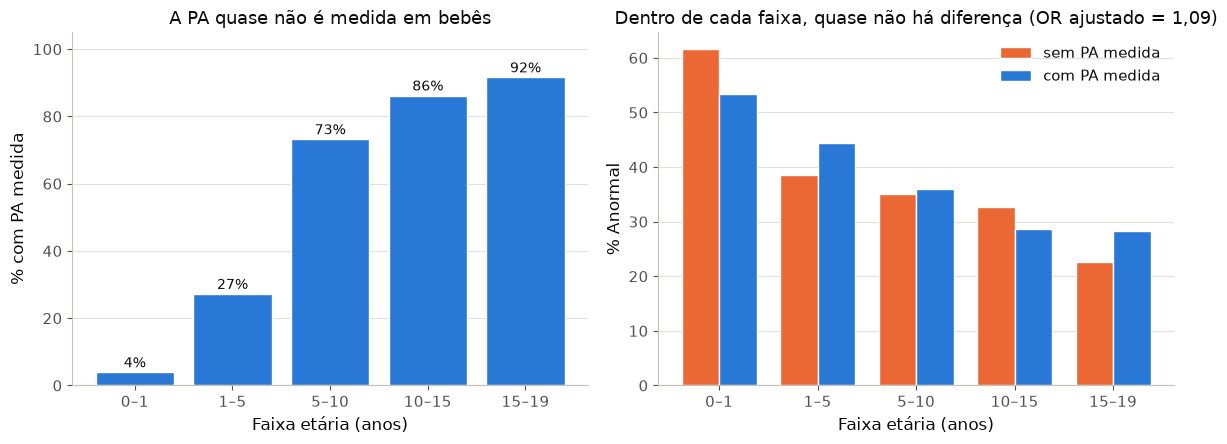

In [19]:
# A ausência de PA é informativa sobre o alvo... ou só sobre a IDADE? Estratificamos por faixa etária.
d = pd.DataFrame({'faixa': faixa_etaria, 'pa_medida': df_limpo['pa_medida'],
                  'anormal': (df_limpo[ALVO] == 'Anormal').astype(int)})

pct_com_pa = d.groupby('faixa', observed=True)['pa_medida'].mean() * 100
pct_anormal = (d.groupby(['faixa', 'pa_medida'], observed=True)['anormal'].mean().unstack() * 100)
n_cel = d.groupby(['faixa', 'pa_medida'], observed=True).size().unstack()

p_faixa = {f: chi2_contingency(pd.crosstab(g['pa_medida'], g['anormal']))[1] for f, g in d.groupby('faixa', observed=True)}
tab_pa = pd.DataFrame({'n': d['faixa'].value_counts().sort_index(),
                       '% com PA medida': pct_com_pa.round(1),
                       '% Anormal sem PA': pct_anormal[0].round(1), 'n sem PA': n_cel[0],
                       '% Anormal com PA': pct_anormal[1].round(1), 'n com PA': n_cel[1],
                       'p (χ² dentro da faixa)': pd.Series(p_faixa).round(3)})
display(tab_pa)
exportar(tab_pa.reset_index().rename(columns={'faixa': 'faixa etária (anos)'}), 'pa_ausente_por_idade')

# Odds ratio bruto x ajustado por faixa (Mantel-Haenszel): OR = 1 significa "sem associação"
num_mh = den_mh = 0.0
for _, g in d.groupby('faixa', observed=True):
    t_ = pd.crosstab(g['pa_medida'], g['anormal']).reindex(index=[0, 1], columns=[0, 1], fill_value=0).to_numpy()
    a_, b_, c_, d_ = t_[1, 1], t_[1, 0], t_[0, 1], t_[0, 0]      # com PA: anormal/normal; sem PA: anormal/normal
    n_ = t_.sum(); num_mh += a_ * d_ / n_; den_mh += b_ * c_ / n_
tb = pd.crosstab(d['pa_medida'], d['anormal']).to_numpy()
or_bruto = (tb[1, 1] * tb[0, 0]) / (tb[1, 0] * tb[0, 1]); or_mh = num_mh / den_mh
print(f'Odds ratio (PA medida -> Anormal): bruto = {num(or_bruto, 2)} | ajustado por faixa etária (Mantel-Haenszel) = {num(or_mh, 2)}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.bar(tab_pa.index.astype(str), tab_pa['% com PA medida'], color=COR['Normal'], edgecolor='white')
for i_, v in enumerate(tab_pa['% com PA medida']): ax1.text(i_, v + 1.5, f'{num(v, 0)}%', ha='center', fontsize=10)
ax1.set_ylim(0, 105); ax1.set_xlabel('Faixa etária (anos)'); ax1.set_ylabel('% com PA medida')
ax1.set_title('A PA quase não é medida em bebês'); ax1.grid(axis='x', visible=False)
x_ = np.arange(len(tab_pa)); w_ = 0.38
ax2.bar(x_ - w_/2, tab_pa['% Anormal sem PA'], w_, color=COR['Anormal'], edgecolor='white', label='sem PA medida')
ax2.bar(x_ + w_/2, tab_pa['% Anormal com PA'], w_, color=COR['Normal'], edgecolor='white', label='com PA medida')
ax2.set_xticks(x_, tab_pa.index.astype(str)); ax2.set_xlabel('Faixa etária (anos)'); ax2.set_ylabel('% Anormal')
ax2.set_title(f'Dentro de cada faixa, quase não há diferença (OR ajustado = {num(or_mh, 2)})')
ax2.legend(frameon=False); ax2.grid(axis='x', visible=False)
fig.tight_layout()
salvar(fig, 'pa_ausente_por_idade')

#### Interpretação
- **A PA quase não é medida em bebês:** só **3,9%** na faixa 0–1 ano, contra **91,6%** aos 15–19.
- **Dentro de cada faixa etária, a diferença no alvo praticamente some:** o OR bruto é **0,61**, mas o OR ajustado por faixa (Mantel-Haenszel) é **1,09**, próximo de 1. Só a faixa 1–5 anos mostra diferença (p = 0,002), e no sentido contrário (44,4% de Anormal com PA × 38,6% sem).
- **Conclusão:** `pa_medida` não carrega informação própria sobre o alvo; é um *proxy* da IDADE. Vale manter como indicador, mas a ausência de PA **não indica doença**: indica que o paciente é pequeno.

## Parte 4 – Evidências para as transformações

Aqui só se calcula e imprime. Nenhuma transformação é aplicada ao `df_limpo`: elas pertencem ao pipeline de modelagem, depois da divisão treino/teste.

,Peso,Altura,IMC,Idade
Peso,1.00,0.98,0.50,0.97
Altura,0.98,1.00,0.37,0.99
IMC,0.50,0.37,1.00,0.36
Idade,0.97,0.99,0.36,1.00


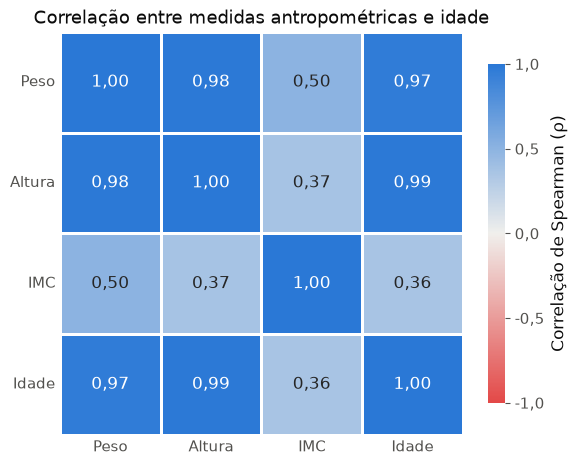

Redundantes (|ρ| ≥ 0,8): Peso e Altura, ρ = 0,98
Redundantes (|ρ| ≥ 0,8): Peso e Idade, ρ = 0,97
Redundantes (|ρ| ≥ 0,8): Altura e Idade, ρ = 0,99


In [20]:
# 1) Correlação entre as medidas antropométricas e a idade. Pares muito correlacionados
# (|ρ| ≥ 0,8) carregam quase a mesma informação, e manter os dois só adiciona redundância.
# Spearman pelos mesmos motivos da Parte 1 (assimetria e relação não necessariamente linear).
ANTROPO = {'Peso': 'Peso', 'Altura': 'Altura', 'IMC': 'IMC', 'IDADE': 'Idade'}
corr = df_limpo[list(ANTROPO)].corr(method='spearman').rename(index=ANTROPO, columns=ANTROPO)
display(corr.round(2))

# Escala divergente (vermelho = negativa, cinza = zero, azul = positiva) fixa de -1 a 1,
# para a cor significar o mesmo em qualquer figura de correlação.
divergente = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, vmin=-1, vmax=1, cmap=divergente, annot=corr.map(lambda v: num(v, 2)).to_numpy(),
            fmt='', annot_kws={'fontsize': 12}, linewidths=2, linecolor='white', square=True,
            cbar_kws={'label': 'Correlação de Spearman (ρ)', 'shrink': 0.8}, ax=ax)
barra = ax.collections[0].colorbar
barra.set_ticks([-1, -0.5, 0, 0.5, 1], labels=[num(v, 1) for v in (-1, -0.5, 0, 0.5, 1)])
ax.set_title('Correlação entre medidas antropométricas e idade')
ax.tick_params(length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
salvar(fig, 'correlacao_antropometricas')

# Pares redundantes, usados na justificativa da tabela de transformações.
pares_redundantes = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.index)
                     for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.8]
for a, b, r in pares_redundantes:
    print(f'Redundantes (|ρ| ≥ 0,8): {a} e {b}, ρ = {num(r, 2)}')

,assimetria
IDADE,0.76
FC,1.27
Peso,1.43
Altura,0.22
IMC,1.22
PA SISTOLICA,1.22
PA DIASTOLICA,0.90


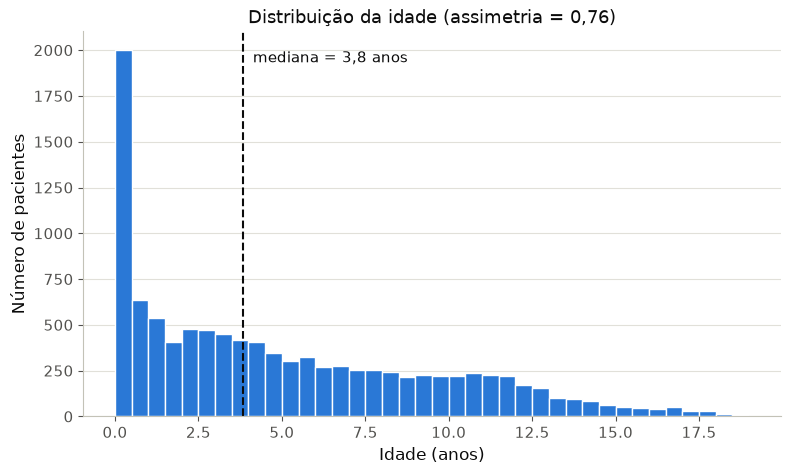

In [21]:
# 2) Assimetria. Acima de 1 em módulo, a distribuição é fortemente assimétrica: médias e
# modelos sensíveis à escala ficam dominados pela cauda, o que justifica log ou faixas.
assimetria = df_limpo[list(NUMERICAS)].skew().round(2).rename('assimetria')
display(assimetria.to_frame())

idade = df_limpo['IDADE']
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(idade, bins=np.arange(0, FAIXAS[-1] + 0.5, 0.5), color=COR_UNICA, edgecolor='white', linewidth=1)
ax.axvline(idade.median(), color=TINTA, linestyle='--', linewidth=1.5)
ax.text(idade.median() + 0.3, ax.get_ylim()[1] * 0.95, f'mediana = {num(idade.median())} anos',
        va='top', fontsize=11, color=TINTA)
ax.set_xlabel('Idade (anos)')
ax.set_ylabel('Número de pacientes')
ax.set_title(f'Distribuição da idade (assimetria = {num(assimetria["IDADE"], 2)})')
ax.grid(axis='x', visible=False)
salvar(fig, 'hist_idade')

In [22]:
# 3) Categorias raras: uma coluna one-hot para uma categoria com poucos casos quase nunca
# vale 1, o modelo não aprende nada com ela e ainda ganha uma variável a mais.
for col in ['PULSOS', 'B2', 'SOPRO']:
    contagem = df_limpo[col].value_counts(dropna=False)
    display(pd.DataFrame({'n': contagem, '%': (contagem / len(df_limpo) * 100).round(1)}).rename_axis(col))

,n,%
PULSOS,,
Normais,10430,98.6
Amplos,43,0.4
Femorais diminuídos,35,0.3
Outro,31,0.3
NaN,24,0.2
Diminuídos,13,0.1


,n,%
B2,,
Normal,10054,95.1
Hiperfonética,248,2.3
Desdobramento fixo,136,1.3
Outro,65,0.6
Única,65,0.6
NaN,8,0.1


,n,%
SOPRO,,
Ausente,6581,62.2
Sistólico,3948,37.3
Contínuo,37,0.3
Diastólico,6,0.1
Sistólico e diastólico,3,0.0
NaN,1,0.0


In [23]:
# 4) Proporção do alvo. Um desbalanceamento leve não pede reamostragem, só divisão
# treino/teste estratificada pelo alvo.
proporcao_alvo = (df_limpo[ALVO].value_counts(normalize=True) * 100).round(1)
display(proporcao_alvo.to_frame('%'))

,%
NORMAL X ANORMAL,
Normal,57.6
Anormal,42.4


In [24]:
# 5) Tabela de transformações propostas. As justificativas usam os números calculados
# acima, para o relatório citar a evidência de cada decisão.
fc_medianas = fc_por_faixa.set_index('faixa etária (anos)')['mediana']
par_pa = df_limpo[['IDADE', 'PA SISTOLICA']].dropna()
rho_pas_idade = spearmanr(par_pa['IDADE'], par_pa['PA SISTOLICA'])[0]
sexo = df_limpo['SEXO'].value_counts()
ppa_n = PPA.value_counts().reindex(PPA.cat.categories)
pulsos = df_limpo['PULSOS'].value_counts()
pct_pulsos_normais = pulsos['Normais'] / pulsos.sum() * 100
raras_sopro = [c for c, n in df_limpo['SOPRO'].value_counts().items() if n < N_MIN]
raras_b2 = [c for c, n in df_limpo['B2'].value_counts().items() if n < N_MIN]


def intensidade(assim):
    """Convenção usual: |assimetria| < 0,5 leve, 0,5–1 moderada, > 1 forte."""
    return 'leve' if abs(assim) < 0.5 else 'moderada' if abs(assim) <= 1 else 'forte'


# Peso/Altura/IMC: sai quem é redundante com a IDADE (|ρ| ≥ 0,8); o IMC combina peso e altura.
redundantes_idade = [c for c in ('Peso', 'Altura') if abs(corr.loc[c, 'Idade']) >= 0.8]
manter = [c for c in ('Peso', 'Altura', 'IMC') if c not in redundantes_idade]
texto_corr = '; '.join(f'{a}–{b}: ρ = {num(r, 2)}' for a, b, r in pares_redundantes) or 'nenhum par com |ρ| ≥ 0,8'

nulos = (df_limpo[list(NUMERICAS) + ['PULSOS', 'B2', 'SOPRO', 'SEXO', 'PPA_calc']]
         .isna().mean().mul(100).round(1))
nulos = nulos[nulos > 0].sort_values(ascending=False)

# numero de episodios x colunas de sintomas, para a linha dessa coluna na tabela.
colunas_sint = [c for c in df_limpo if c.startswith('sint_')]
episodios_iguais = df_limpo['numero de episodios'] == df_limpo[colunas_sint].sum(axis=1)
n_assintomaticos = int(df_limpo['sint_assintomatico'].sum())
texto_nulos = ', '.join(f'{c} {num(v)}%' for c, v in nulos.items())

transformacoes = pd.DataFrame([
    {'variável': 'NORMAL X ANORMAL e SEXO', 'transformação proposta': 'binária 0/1',
     'justificativa': (f'Duas categorias cada: alvo Normal {num(proporcao_alvo["Normal"])}% / '
                       f'Anormal {num(proporcao_alvo["Anormal"])}%; SEXO M = {fmt_n(sexo["M"])}, '
                       f'F = {fmt_n(sexo["F"])}.')},
    {'variável': 'SOPRO e B2', 'transformação proposta': 'one-hot',
     'justificativa': (f'Nominais sem ordem (SOPRO: {df_limpo["SOPRO"].nunique()} categorias; '
                       f'B2: {df_limpo["B2"].nunique()}); one-hot não impõe uma ordem inexistente. '
                       f'Categorias com n < 30 agrupadas antes: SOPRO {", ".join(raras_sopro) or "nenhuma"}; '
                       f'B2 {", ".join(raras_b2) or "nenhuma"}.')},
    {'variável': 'PULSOS', 'transformação proposta': 'agregação Normal/Alterado + binária',
     'justificativa': (f'{num(pct_pulsos_normais)}% dos registros são "Normais"; as outras '
                       f'{len(pulsos) - 1} categorias somam {fmt_n(pulsos.drop("Normais").sum())} casos, '
                       f'poucos demais para colunas próprias.')},
    {'variável': 'PPA (recalculada)', 'transformação proposta':
         'ordinal (Normal < Pré-hipertensão < HAS estágio 1 < HAS estágio 2)',
     'justificativa': ('Categorias com ordem clínica crescente; n por nível: '
                       + ', '.join(f'{c} {fmt_n(n)}' for c, n in ppa_n.items())
                       + f'. {num(PPA.isna().mean() * 100)}% nulos (sem PA medida).')},
    {'variável': 'FC e PA', 'transformação proposta': 'z-score por faixa etária',
     'justificativa': (f'Dependem da idade: FC x IDADE ρ = {num(rho_fc_idade, 2)} (mediana da FC de '
                       f'{num(fc_medianas.iloc[0], 0)} bpm aos 0–1 ano a {num(fc_medianas.iloc[-1], 0)} bpm aos '
                       f'{ROTULOS_FAIXAS[-1]}); PAS x IDADE ρ = {num(rho_pas_idade, 2)}. O z por faixa compara cada '
                       f'criança com as da mesma idade. {conclusao_fc}')},
    {'variável': 'Peso, Altura e IMC', 'transformação proposta':
         f'manter apenas os não redundantes: {", ".join(manter)} (além da IDADE)',
     'justificativa': (f'Pares com |ρ| ≥ 0,8: {texto_corr}. '
                       f'IMC x Idade: ρ = {num(corr.loc["IMC", "Idade"], 2)}.')},
    {'variável': 'IDADE', 'transformação proposta': 'log(1 + idade) ou faixas etárias',
     'justificativa': (f'Assimetria {intensidade(assimetria["IDADE"])} ({num(assimetria["IDADE"], 2)}), '
                       f'com cauda à direita; mediana de '
                       f'{num(df_limpo["IDADE"].median())} anos, com '
                       f'{num((df_limpo["IDADE"] < 1).mean() * 100)}% dos pacientes abaixo de 1 ano.')},
    {'variável': 'Numéricas', 'transformação proposta': 'padronização z-score ajustada só no treino',
     'justificativa': (f'Escalas muito diferentes (ex.: Peso até {num(df_limpo["Peso"].max(), 0)} kg, '
                       f'FC até {num(df_limpo["FC"].max(), 0)} bpm); média e desvio vindos só do treino '
                       'evitam vazamento de informação do teste.')},
    {'variável': 'Nulos restantes', 'transformação proposta':
         'imputação por mediana (numéricas) ou moda (categóricas) após a divisão treino/teste',
     'justificativa': (f'Ainda há nulos: {texto_nulos}. A mediana resiste à assimetria. A ausência de PA '
                       'não é aleatória (etapa 8 da limpeza), então pa_medida acompanha a imputação. '
                       f'Na PPA_calc, com {num(PPA.isna().mean() * 100)}% de nulos, a moda rotularia quase '
                       'todos como "Normal": ali a ausência deve virar uma categoria própria ("sem PA").')},
    {'variável': 'PPA_PAS_calc, PPA_PAD_calc e z_altura', 'transformação proposta': 'remover',
     'justificativa': ('Colunas intermediárias do cálculo da PPA: a PPA_calc já é, por definição, a pior '
                       'classificação entre PAS e PAD, e a z_altura só serviu para classificar a pressão '
                       '(é função de Altura, IDADE e SEXO, que já estão na base).')},
    {'variável': 'numero de episodios', 'transformação proposta': 'remover',
     'justificativa': (f'Veio da primeira versão da limpeza. Coincide com a soma das colunas sint_* em '
                       f'{num(episodios_iguais.mean() * 100, 2)}% das linhas e conta "Assintomático" como '
                       f'episódio ({fmt_n(n_assintomaticos)} pacientes); sint_* e hda_ausente já carregam '
                       'essa informação.')},
    {'variável': 'ID', 'transformação proposta': 'remover',
     'justificativa': (f'Identificador sem informação clínica ({fmt_n(df_limpo["ID"].nunique())} valores '
                       f'únicos em {fmt_n(len(df_limpo))} linhas). grupo_paciente também sai do modelo: '
                       'serve só para a divisão treino/teste por paciente.')},
])
display(transformacoes)
exportar(transformacoes, 'transformacoes')

,variável,transformação proposta,justificativa
0,NORMAL X ANORMAL e SEXO,binária 0/1,"Duas categorias cada: alvo Normal 57,6% / Anormal 42,4%; SEXO M = 5.985, F = 4.122."
1,SOPRO e B2,one-hot,"Nominais sem ordem (SOPRO: 5 categorias; B2: 5); one-hot não impõe uma ordem inexistente. Categorias com n < 30 agrupadas antes: SOPRO Diastólico, Sistólico e diastólico; B2 nenhuma."
2,PULSOS,agregação Normal/Alterado + binária,"98,8% dos registros são ""Normais""; as outras 4 categorias somam 122 casos, poucos demais para colunas próprias."
3,PPA (recalculada),ordinal (Normal < Pré-hipertensão < HAS estágio 1 < HAS estágio 2),"Categorias com ordem clínica crescente; n por nível: Normal 2.125, Pré-hipertensão 212, HAS estágio 1 169, HAS estágio 2 40. 75,9% nulos (sem PA medida)."
4,FC e PA,z-score por faixa etária,"Dependem da idade: FC x IDADE ρ = -0,69 (mediana da FC de 112 bpm aos 0–1 ano a 78 bpm aos 15–19); PAS x IDADE ρ = 0,42. O z por faixa compara cada criança com as da mesma idade. A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade."
5,"Peso, Altura e IMC",manter apenas os não redundantes: IMC (além da IDADE),"Pares com |ρ| ≥ 0,8: Peso–Altura: ρ = 0,98; Peso–Idade: ρ = 0,97; Altura–Idade: ρ = 0,99. IMC x Idade: ρ = 0,36."
6,IDADE,log(1 + idade) ou faixas etárias,"Assimetria moderada (0,76), com cauda à direita; mediana de 3,8 anos, com 25,0% dos pacientes abaixo de 1 ano."
7,Numéricas,padronização z-score ajustada só no treino,"Escalas muito diferentes (ex.: Peso até 118 kg, FC até 250 bpm); média e desvio vindos só do treino evitam vazamento de informação do teste."
8,Nulos restantes,imputação por mediana (numéricas) ou moda (categóricas) após a divisão treino/teste,"Ainda há nulos: PPA_calc 75,9%, PA DIASTOLICA 57,0%, PA SISTOLICA 56,9%, IMC 34,9%, Altura 31,5%, Peso 17,6%, FC 5,7%, SEXO 4,4%, PULSOS 0,2%, B2 0,1%. A mediana resiste à assimetria. A ausência de PA não é aleatória (etapa 8 da limpeza), então pa_medida acompanha a imputação. Na PPA_calc, com 75,9% de nulos, a moda rotularia quase todos como ""Normal"": ali a ausência deve virar uma categoria própria (""sem PA"")."
9,"PPA_PAS_calc, PPA_PAD_calc e z_altura",remover,"Colunas intermediárias do cálculo da PPA: a PPA_calc já é, por definição, a pior classificação entre PAS e PAD, e a z_altura só serviu para classificar a pressão (é função de Altura, IDADE e SEXO, que já estão na base)."


## Resumo dos achados

In [25]:
# Resumo gerado a partir dos resultados, sem números digitados à mão: se os dados
# mudarem, o texto acompanha.
testadas = resumo[resumo['teste'] == 'qui-quadrado']
top = testadas.head(3)
print('PARTE 1 – FC x IDADE')
print(f'  A base bruta tinha {fora_faixa.sum()} pontos impossíveis (FC fora de 40–250 bpm ou idade fora de '
      f'{FAIXAS[0]}–{FAIXAS[-1]} anos), eliminados na limpeza. Na base limpa, a FC cai com a idade '
      f'(Spearman ρ = {num(rho_fc_idade, 2)}, {p_txt(p_fc_idade)}): mediana de '
      f'{num(fc_medianas.iloc[0], 0)} bpm aos 0–1 ano e {num(fc_medianas.iloc[-1], 0)} bpm aos {ROTULOS_FAIXAS[-1]}.')
print('\nPARTE 2 – Variáveis x alvo')
print(f'  {(testadas["significativo (α = 0,05)"] == "sim").sum()} de {len(testadas)} variáveis testadas têm '
      'p < 0,05, o esperado com n grande. As maiores diferenças de % Anormal:')
for _, linha in top.iterrows():
    print(f'  - {linha["variável"]}: {linha["resumo do efeito"]} ({num(linha["diferença (p.p.)"])} p.p.)')
print('\nPARTE 3 – Confundimento FC x IDADE')
print(f'  {conclusao_fc}')
print('\nPARTE 4 – Transformações')
print(f'  Pares redundantes (|ρ| ≥ 0,8): {texto_corr}.')
print(f'  IDADE com assimetria {num(assimetria["IDADE"], 2)}; PULSOS com {num(pct_pulsos_normais)}% "Normais"; '
      f'alvo {num(proporcao_alvo["Normal"])}% Normal / {num(proporcao_alvo["Anormal"])}% Anormal '
      '(desbalanceamento leve, sem necessidade de reamostragem).')

PARTE 1 – FC x IDADE
  A base bruta tinha 203 pontos impossíveis (FC fora de 40–250 bpm ou idade fora de 0–19 anos), eliminados na limpeza. Na base limpa, a FC cai com a idade (Spearman ρ = -0,69, p < 0,001): mediana de 112 bpm aos 0–1 ano e 78 bpm aos 15–19.

PARTE 2 – Variáveis x alvo
  31 de 40 variáveis testadas têm p < 0,05, o esperado com n grande. As maiores diferenças de % Anormal:
  - SOPRO: % Anormal: Sistólico = 95,9% vs Ausente = 10,1% (85,8 p.p.)
  - B2: % Anormal: Hiperfonética = 98,0% vs Normal = 39,7% (58,2 p.p.)
  - PULSOS: % Anormal: Femorais diminuídos = 94,3% vs Normais = 41,9% (52,4 p.p.)

PARTE 3 – Confundimento FC x IDADE
  A associação diminuiu bastante depois de ajustar pela idade (30,5 → 14,2 p.p.): boa parte dela era explicada pela idade.

PARTE 4 – Transformações
  Pares redundantes (|ρ| ≥ 0,8): Peso–Altura: ρ = 0,98; Peso–Idade: ρ = 0,97; Altura–Idade: ρ = 0,99.
  IDADE com assimetria 0,76; PULSOS com 98,8% "Normais"; alvo 57,6% Normal / 42,4% Anormal (desb

## Parte 5 – Acréscimos à tabela de transformações

Decisões que faltavam na tabela da Parte 4, cada uma com a evidência calculada: risco de vazamento de informação, colunas binárias raras, `pa_medida` como *proxy* da idade, imputação por faixa etária, PPA ordinal com dois indicadores (PA medida e PPA calculada), indicador de sexo ausente, IDADE em log e divisão treino/teste por paciente. A tabela completa vai para `tabelas/transformacoes_completa.csv`.

In [26]:
# Acrescenta à tabela do grupo (gerada na célula anterior) as decisões que faltavam, com a evidência calculada
rs = forca_cat.set_index('variável')['V de Cramér']
raras_bin = [c for c in df_limpo if (c.startswith('sint_') or c.startswith('motivo_')) and df_limpo[c].sum() < N_MIN]
n_grupos_rep = int((df_limpo.groupby('grupo_paciente').size() > 1).sum())
com_pa_sem_ppa = (df_limpo['pa_medida'] == 1) & df_limpo['PPA_calc'].isna()
sem_altura = com_pa_sem_ppa & df_limpo['z_altura'].isna()
pct_anormal = lambda m: (df_limpo.loc[m, ALVO] == 'Anormal').mean() * 100
sexo_nulo = df_limpo['SEXO'].isna()

extras = pd.DataFrame([
    {'variável': 'SOPRO, B2, PULSOS e motivo_*', 'transformação proposta':
        'manter, mas SINALIZAR risco de vazamento e comparar cenários com e sem elas',
     'justificativa': (f'São achados do próprio exame/consulta (V de Cramér: SOPRO {num(rs["SOPRO"], 2)}, '
                       f'MOTIVO1 {num(rs["MOTIVO1"], 2)}, B2 {num(rs["B2"], 2)}). "Cardiopatia já estabelecida" ou '
                       '"sopro" como motivo já revelam o desfecho; um modelo que só os usa "acerta" em parte porque o '
                       'rótulo já está embutido neles. Na A2, treinar com e sem esse grupo.')},
    {'variável': f'colunas binárias raras ({len(raras_bin)})', 'transformação proposta':
        'agrupar em uma única coluna motivo_raro',
     'justificativa': (f'{", ".join(f"{c} ({int(df_limpo[c].sum())})" for c in raras_bin)} têm menos de {N_MIN} casos '
                       'positivos: não dá para aprender nada com elas e não foram testadas na bivariada.')},
    {'variável': 'pa_medida', 'transformação proposta':
        'manter como indicador, sabendo que funciona como "proxy" da idade',
     'justificativa': (f'A ausência de PA parece informativa (OR bruto {num(or_bruto, 2)}), mas dentro de cada faixa etária '
                       f'a associação some (OR ajustado {num(or_mh, 2)}): a PA falta porque bebês quase não têm PA '
                       f'medida ({num(pct_com_pa.iloc[0], 0)}% na faixa 0–1 ano). Ou seja, carrega a informação da IDADE.')},
    {'variável': 'Imputação (refinamento)', 'transformação proposta':
        'mediana POR FAIXA ETÁRIA (e não global), calculada só no treino',
     'justificativa': ('FC e PA variam muito com a idade; preencher um bebê com a mediana geral da base criaria valores '
                       'incoerentes. A mediana da própria faixa é mais realista e continua resistente à assimetria.')},
    {'variável': 'PPA_calc', 'transformação proposta':
        'ordinal 0–3 + indicadores pa_medida e ppa_calculada (sem PPA = 0 com ppa_calculada = 0)',
     'justificativa': ('Mantém a ordem clínica sem imputar a moda '
                       f'({num(PPA.isna().mean() * 100)}% nulos). Só pa_medida não basta: {fmt_n(com_pa_sem_ppa.sum())} '
                       f'pacientes têm PA medida mas PPA não calculável ({fmt_n(sem_altura.sum())} deles sem altura; '
                       'o Fourth Report também só cobre 1 a 17 anos) e, sem o segundo indicador, ficariam iguais aos '
                       'de PPA "Normal".')},
    {'variável': 'SEXO (nulos)', 'transformação proposta':
        'moda aprendida no treino + indicador sexo_ausente',
     'justificativa': (f'{fmt_n(sexo_nulo.sum())} pacientes sem sexo registrado têm {num(pct_anormal(sexo_nulo))}% de '
                       f'Anormais, contra {num(pct_anormal(~sexo_nulo))}% dos demais: a ausência carrega informação, que '
                       'a moda sozinha apagaria (mesmo raciocínio de hda_ausente).')},
    {'variável': 'IDADE (implementação)', 'transformação proposta':
        'z-score de log(1 + idade), ajustado só no treino',
     'justificativa': (f'Concretiza a linha da IDADE acima: o log reduz a assimetria de '
                       f'{num(df_limpo["IDADE"].skew(), 2)} para {num(np.log1p(df_limpo["IDADE"]).skew(), 2)} '
                       'e separa melhor as idades do primeiro ano, onde se concentram os Anormais.')},
    {'variável': 'Divisão treino/teste', 'transformação proposta':
        'StratifiedGroupKFold: estratificada pelo alvo e agrupada por grupo_paciente',
     'justificativa': (f'{n_grupos_rep} grupos têm mais de uma linha (mesmo paciente na mesma consulta). Se ficassem '
                       'separados entre treino e teste, o modelo "reveria" o mesmo paciente e as métricas ficariam otimistas.')},
], columns=transformacoes.columns)

transformacoes_final = pd.concat([transformacoes, extras], ignore_index=True)
pd.set_option('display.max_colwidth', 220)
display(transformacoes_final)
exportar(transformacoes_final, 'transformacoes_completa')

,variável,transformação proposta,justificativa
0,NORMAL X ANORMAL e SEXO,binária 0/1,"Duas categorias cada: alvo Normal 57,6% / Anormal 42,4%; SEXO M = 5.985, F = 4.122."
1,SOPRO e B2,one-hot,"Nominais sem ordem (SOPRO: 5 categorias; B2: 5); one-hot não impõe uma ordem inexistente. Categorias com n < 30 agrupadas antes: SOPRO Diastólico, Sistólico e diastólico; B2 nenhuma."
2,PULSOS,agregação Normal/Alterado + binária,"98,8% dos registros são ""Normais""; as outras 4 categorias somam 122 casos, poucos demais para colunas próprias."
3,PPA (recalculada),ordinal (Normal < Pré-hipertensão < HAS estágio 1 < HAS estágio 2),"Categorias com ordem clínica crescente; n por nível: Normal 2.125, Pré-hipertensão 212, HAS estágio 1 169, HAS estágio 2 40. 75,9% nulos (sem PA medida)."
4,FC e PA,z-score por faixa etária,"Dependem da idade: FC x IDADE ρ = -0,69 (mediana da FC de 112 bpm aos 0–1 ano a 78 bpm aos 15–19); PAS x IDADE ρ = 0,42. O z por faixa compara cada criança com as da mesma idade. A associação diminuiu bastante depois..."
5,"Peso, Altura e IMC",manter apenas os não redundantes: IMC (além da IDADE),"Pares com |ρ| ≥ 0,8: Peso–Altura: ρ = 0,98; Peso–Idade: ρ = 0,97; Altura–Idade: ρ = 0,99. IMC x Idade: ρ = 0,36."
6,IDADE,log(1 + idade) ou faixas etárias,"Assimetria moderada (0,76), com cauda à direita; mediana de 3,8 anos, com 25,0% dos pacientes abaixo de 1 ano."
7,Numéricas,padronização z-score ajustada só no treino,"Escalas muito diferentes (ex.: Peso até 118 kg, FC até 250 bpm); média e desvio vindos só do treino evitam vazamento de informação do teste."
8,Nulos restantes,imputação por mediana (numéricas) ou moda (categóricas) após a divisão treino/teste,"Ainda há nulos: PPA_calc 75,9%, PA DIASTOLICA 57,0%, PA SISTOLICA 56,9%, IMC 34,9%, Altura 31,5%, Peso 17,6%, FC 5,7%, SEXO 4,4%, PULSOS 0,2%, B2 0,1%. A mediana resiste à assimetria. A ausência de PA não é aleatória..."
9,"PPA_PAS_calc, PPA_PAD_calc e z_altura",remover,"Colunas intermediárias do cálculo da PPA: a PPA_calc já é, por definição, a pior classificação entre PAS e PAD, e a z_altura só serviu para classificar a pressão (é função de Altura, IDADE e SEXO, que já estão na base)."


## Parte 6 – Aplicando as transformações (pré-processador que aprende só no treino)

Implementação da tabela acima. A classe tem dois métodos:
- `fit(treino)`: **aprende** medianas, médias, desvios, modas e categorias frequentes **só com o treino**;
- `transform(qualquer_df)`: **aplica** o que foi aprendido (treino, teste ou dados novos).

Produz `IDADE_log_z` (z-score de log(1 + idade)) e `IMC_z` (z-score global); `FC_z`, `PAS_z` e `PAD_z` (z-score **por faixa etária**); `pa_medida`, `PPA_ord` e `ppa_calculada`; `SEXO_M` e `sexo_ausente`; `pulsos_alterados`; one-hot de SOPRO e B2 (categorias com menos de 30 casos no treino → `_raras`; a categoria real "Outro" da B2 fica com coluna própria); `sint_*`, `motivo_*` e `motivo_raro`. **Saem do modelo:** ID, `grupo_paciente`, Peso, Altura, `z_altura`, `PPA_PAS_calc`, `PPA_PAD_calc` e `numero de episodios`.

A divisão treino/teste é estratificada pelo alvo e agrupada por `grupo_paciente` (`StratifiedGroupKFold`), para o mesmo paciente não aparecer nos dois lados.

In [27]:
from sklearn.model_selection import StratifiedGroupKFold

FAIXAS_IDADE = FAIXAS                                # as mesmas faixas da limpeza e da bivariada

class PreprocessadorUCMF:
    """Aplica as transformações da tabela acima.
    fit(df_treino)  -> APRENDE medianas, médias, desvios, modas e categorias frequentes SÓ NO TREINO.
    transform(df)   -> aplica o que foi aprendido (serve para treino, teste ou dados novos)."""

    Z_FAIXA = ['FC', 'PA SISTOLICA', 'PA DIASTOLICA']    # z-score dentro da faixa etária
    Z_GLOBAL = ['IDADE_log', 'IMC']                      # z-score global; IDADE entra como log(1 + idade)
                                                         # (Peso e Altura saem: redundantes com a IDADE)
    ORDEM_PPA = {'Normal': 0, 'Pré-hipertensão': 1, 'HAS estágio 1': 2, 'HAS estágio 2': 3}

    def __init__(self, min_casos=30):
        self.min_casos = min_casos

    def _faixa(self, idade):
        return pd.cut(idade, FAIXAS_IDADE, include_lowest=True, labels=False)

    def _imputar(self, df):
        d = df.copy()
        faixa = self._faixa(d['IDADE'])
        for c in self.Z_FAIXA + ['IMC']:
            med = faixa.map(self.mediana_faixa_[c]).astype(float)
            d[c] = d[c].fillna(med).fillna(self.mediana_global_[c])
        d['IDADE_log'] = np.log1p(d['IDADE'])          # reduz a assimetria da idade
        return d

    def fit(self, df):
        faixa = self._faixa(df['IDADE'])
        cols_med = self.Z_FAIXA + ['IMC']
        self.mediana_faixa_ = {c: df[c].groupby(faixa).median() for c in cols_med}
        self.mediana_global_ = {c: df[c].median() for c in cols_med}
        d = self._imputar(df)
        self.media_faixa_ = {c: d[c].groupby(faixa).mean() for c in self.Z_FAIXA}
        self.dp_faixa_ = {c: d[c].groupby(faixa).std() for c in self.Z_FAIXA}
        self.media_glob_ = {c: d[c].mean() for c in self.Z_GLOBAL}
        self.dp_glob_ = {c: d[c].std() for c in self.Z_GLOBAL}
        self.moda_ = {c: df[c].mode().iloc[0] for c in ['SEXO', 'SOPRO', 'B2', 'PULSOS']}
        self.cat_freq_ = {c: [k for k, n in df[c].fillna(self.moda_[c]).value_counts().items() if n >= self.min_casos]
                          for c in ['SOPRO', 'B2']}
        # categorias com n < min_casos no treino: juntas numa coluna '<var>_raras' (só criada se houver alguma)
        self.cat_raras_ = {c: sorted(set(df[c].dropna()) - set(self.cat_freq_[c])) for c in ['SOPRO', 'B2']}
        self.bin_cols_ = [c for c in df if c.startswith('sint_') or c.startswith('motivo_')]
        self.bin_raras_ = [c for c in self.bin_cols_ if df[c].sum() < self.min_casos]
        return self

    def transform(self, df):
        d = self._imputar(df)
        faixa = self._faixa(d['IDADE'])
        X = pd.DataFrame(index=df.index)
        # numéricas: z-score global (IDADE, IMC) e z-score por faixa etária (FC, PAS, PAD)
        for c in self.Z_GLOBAL:
            X[f'{c}_z'] = (d[c] - self.media_glob_[c]) / self.dp_glob_[c]
        for c, nome in [('FC', 'FC_z'), ('PA SISTOLICA', 'PAS_z'), ('PA DIASTOLICA', 'PAD_z')]:
            X[nome] = (d[c] - faixa.map(self.media_faixa_[c])) / faixa.map(self.dp_faixa_[c])
        # pressão: indicador + PPA ordinal (sem PA = 0, distinguido pelo indicador)
        X['pa_medida'] = df['pa_medida'].astype(int)
        X['PPA_ord'] = df['PPA_calc'].map(self.ORDEM_PPA).fillna(0).astype(int)
        X['ppa_calculada'] = df['PPA_calc'].notna().astype(int)        # separa PPA "Normal" de PPA não calculada
        # binárias e one-hot
        X['SEXO_M'] = (df['SEXO'].fillna(self.moda_['SEXO']) == 'M').astype(int)
        X['sexo_ausente'] = df['SEXO'].isna().astype(int)              # a ausência de sexo é informativa
        X['pulsos_alterados'] = (df['PULSOS'].fillna(self.moda_['PULSOS']) != 'Normais').astype(int)
        for c in ['SOPRO', 'B2']:
            v = df[c].fillna(self.moda_[c])
            for cat in self.cat_freq_[c]:
                X[f'{c}_{cat}'] = (v == cat).astype(int)
            # categorias raras (n < 30 no treino). Não se chama '_Outro' porque a B2 tem uma categoria
            # real "Outro", cuja coluna seria sobrescrita.
            if self.cat_raras_[c]:
                X[f'{c}_raras'] = (~v.isin(self.cat_freq_[c])).astype(int)
        # sintomas e motivos (já são 0/1); colunas raras viram uma só
        ok = [c for c in self.bin_cols_ if c not in self.bin_raras_]
        X[ok] = df[ok].astype(int)
        X['motivo_raro'] = df[self.bin_raras_].max(axis=1).astype(int) if self.bin_raras_ else 0
        X[['hda_ausente', 'motivo_ausente']] = df[['hda_ausente', 'motivo_ausente']].astype(int)
        return X

def grupo_da_coluna(c):
    if c.startswith(('SOPRO_', 'B2_')) or c == 'pulsos_alterados': return 'achados_exame_fisico'
    if c.startswith('motivo_'): return 'motivo_consulta'
    if c.startswith('sint_') or c == 'hda_ausente': return 'sintomas'
    if c in ('IDADE_log_z', 'IMC_z'): return 'antropometria'
    if c in ('FC_z', 'PAS_z', 'PAD_z', 'PPA_ord', 'pa_medida', 'ppa_calculada'): return 'sinais_vitais_e_pressao'
    if c in ('SEXO_M', 'sexo_ausente'): return 'demografica'
    return 'outro'

# ---- divisão treino/teste por paciente, estratificada pelo alvo ----
dados = df_limpo.copy()
y_all = (dados[ALVO] == 'Anormal').astype(int)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_tr, idx_te = next(sgkf.split(dados, y_all, groups=dados['grupo_paciente']))
tr, te = dados.iloc[idx_tr], dados.iloc[idx_te]

prep = PreprocessadorUCMF(min_casos=N_MIN).fit(tr)       # <- aprende SÓ no treino
X_tr, X_te = prep.transform(tr), prep.transform(te)      # <- aplica nos dois
y_tr, y_te = y_all.iloc[idx_tr], y_all.iloc[idx_te]

print(f'treino: {X_tr.shape} | teste: {X_te.shape}')
print('grupos em comum entre treino e teste:', len(set(tr['grupo_paciente']) & set(te['grupo_paciente'])), '(deve ser 0)')
print(f'% Anormal — treino: {y_tr.mean()*100:.1f} | teste: {y_te.mean()*100:.1f}')
print('nulos após transformar — treino:', int(X_tr.isna().sum().sum()), '| teste:', int(X_te.isna().sum().sum()))
print('colunas raras agrupadas em motivo_raro:', prep.bin_raras_)
print('categorias frequentes — SOPRO:', prep.cat_freq_['SOPRO'], '| B2:', prep.cat_freq_['B2'])
print('categorias raras (coluna _raras) — SOPRO:', prep.cat_raras_['SOPRO'], '| B2:', prep.cat_raras_['B2'])
print('pacientes com B2_Outro = 1 (treino + teste):', int(X_tr['B2_Outro'].sum() + X_te['B2_Outro'].sum()))

treino: (8460, 47) | teste: (2116, 47)
grupos em comum entre treino e teste: 0 (deve ser 0)
% Anormal — treino: 42.4 | teste: 42.4
nulos após transformar — treino: 0 | teste: 0
colunas raras agrupadas em motivo_raro: ['motivo_uso_de_cisaprida', 'motivo_alteracoes_de_pulso_perfusao', 'motivo_cansaco', 'motivo_cardiopatia_na_familia', 'motivo_cianose_e_dispneia']
categorias frequentes — SOPRO: ['Ausente', 'Sistólico', 'Contínuo'] | B2: ['Normal', 'Hiperfonética', 'Desdobramento fixo', 'Outro', 'Única']
categorias raras (coluna _raras) — SOPRO: ['Diastólico', 'Sistólico e diastólico'] | B2: []
pacientes com B2_Outro = 1 (treino + teste): 65


#### O que conferir na saída
- **Grupos em comum entre treino e teste = 0**: nenhum paciente aparece nos dois lados.
- A % de Anormal é a mesma no treino e no teste (42,4% nos dois), porque a divisão é **estratificada**.
- **Nulos após transformar = 0** nos dois conjuntos, com medianas, médias e desvios vindos **só do treino**.
- As categorias frequentes são decididas no treino: nesta divisão, SOPRO "Contínuo" tem 30 casos ou mais e ganha coluna própria; Diastólico e "Sistólico e diastólico" vão para `SOPRO_raras`. Na B2 todas as categorias são frequentes, e a categoria real "Outro" (65 pacientes) tem coluna própria.
- Na validação cruzada da A2, o `fit` deve ser refeito **dentro de cada dobra** (ou usar `Pipeline` do scikit-learn).
- As colunas one-hot de SOPRO e B2 somam 1 dentro de cada variável. Para **regressão logística**, descarte uma coluna de cada grupo (armadilha da variável *dummy*); para árvores, não faz diferença.

In [28]:
# Exporta as matrizes prontas para a A2 e o mapa coluna -> grupo (para os cenários com/sem vazamento)
(PASTA / 'modelagem').mkdir(exist_ok=True)
X_tr.assign(alvo=y_tr.values, grupo_paciente=tr['grupo_paciente'].values).to_csv(PASTA / 'modelagem' / 'treino.csv', index=False)
X_te.assign(alvo=y_te.values, grupo_paciente=te['grupo_paciente'].values).to_csv(PASTA / 'modelagem' / 'teste.csv', index=False)

mapa_colunas = pd.DataFrame({'coluna': X_tr.columns, 'grupo': [grupo_da_coluna(c) for c in X_tr.columns]})
mapa_colunas.to_csv(PASTA / 'modelagem' / 'colunas_por_grupo.csv', index=False)
print(mapa_colunas.groupby('grupo').size().rename('nº de colunas').to_string())

sem_vazamento = mapa_colunas.loc[~mapa_colunas['grupo'].isin(['achados_exame_fisico', 'motivo_consulta']), 'coluna'].tolist()
print(f'\nCenário A (todas): {X_tr.shape[1]} colunas | Cenário B (sem exame físico e sem motivo): {len(sem_vazamento)} colunas')
print('Cenário B:', sem_vazamento)

grupo
achados_exame_fisico       10
antropometria               2
demografica                 2
motivo_consulta            18
sinais_vitais_e_pressao     6
sintomas                    9

Cenário A (todas): 47 colunas | Cenário B (sem exame físico e sem motivo): 19 colunas
Cenário B: ['IDADE_log_z', 'IMC_z', 'FC_z', 'PAS_z', 'PAD_z', 'pa_medida', 'PPA_ord', 'ppa_calculada', 'SEXO_M', 'sexo_ausente', 'sint_assintomatico', 'sint_cianose', 'sint_desmaio_tontura', 'sint_dispneia', 'sint_dor_precordial', 'sint_ganho_de_peso', 'sint_outro', 'sint_palpitacao', 'hda_ausente']


#### Cenários A × B para a A2
O arquivo `modelagem/colunas_por_grupo.csv` marca cada coluna com o seu grupo. O **cenário A** usa todas as 47 colunas; o **cenário B** (19 colunas) tira `achados_exame_fisico` e `motivo_consulta`, que têm risco de vazamento. Comparar o desempenho dos dois responde à pergunta: *o modelo prevê a doença ou só repete o que o médico já anotou?*